# Practical 4: Solutions to the Exercises

## Training, Validation and Testing: Generalisation, Overfitting and Model Selection

This notebook contains complete worked solutions to the five exercises at the end of Practical 4. Each exercise is
laid out in the same way:

1. **Task**: the exercise, restated so this notebook can be read on its own.
2. **Concept**: the idea behind the exercise, explained before any code.
3. **Code**: every line carries a comment saying what it does.
4. **Line by line**: a walk through the cell in order, explaining each line or small group of lines.
5. **Reading the output**: what the printed numbers and the plots mean.
6. **Answer**: a direct answer to each written question of the exercise.

**How to run it.** Use *Kernel → Restart & Run All*. The whole notebook takes about four minutes, most of it in
Exercises 1, 2 and 5, which fit a few thousand small models.

**Section S (setup)** re-creates every function, dataset, split and result of the practical that the exercises
need. It is copied from the practical, nothing in it is new, and it ends by printing a few numbers so you can check
that they agree with the practical exactly.

**About random numbers.** In the practical, the shared generator `rng` was already used in section 7f before the
exercises, so its state when you reach the exercises depends on which cells you ran and how many times. To make
these solutions reproducible, the exercises that need random numbers create their own seeded generator
(`rng_ex2` in Exercise 2, `rng_ex4` in Exercise 4). If you used `rng` in your own solution, your numbers will
differ in the details, but the patterns and the conclusions will be the same.

**The test sets.** The rules of the practical still hold. The classification test set (`X_test`, `y_test`) is used
only once, in the setup, to re-create the single number of section 7e (the same model, so the same number; nothing
is chosen from it). The regression test set (`Xr_test`, `yr_test`) is used exactly once, in Exercise 3, step 4.

**Contents**

- S. Setup: everything from the practical that the exercises use
- Exercise 1: Leave-one-out cross-validation
- Exercise 2: Stratification when one class is rare
- Exercise 3: Model selection for regression, end to end
- Exercise 4: Data leakage
- Exercise 5: The one-standard-error rule and nested cross-validation
- Summary of the answers

## S. Setup: everything from the practical that the exercises use

### S1. Imports and display settings

In [ ]:
import numpy as np                                   # arrays, random numbers, all the numerical work
import pandas as pd                                  # tables, so results print with readable labels
import matplotlib.pyplot as plt                      # every plot in this notebook

from sklearn.datasets import load_breast_cancer, load_diabetes      # the two datasets of the practical
from sklearn.base import clone                       # makes a fresh, untrained copy of a model
from sklearn.pipeline import make_pipeline, Pipeline # chain "standardise, then model" into one object
from sklearn.preprocessing import StandardScaler     # rescales every feature to mean 0, std 1
from sklearn.neighbors import KNeighborsClassifier   # k-nearest-neighbour classifier
from sklearn.linear_model import LogisticRegression  # logistic regression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor   # decision trees

# Library tools. As in the practical, they are used ONLY to check our own code.
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV

%matplotlib inline

np.set_printoptions(precision=4, suppress=True)      # print arrays with 4 decimals, no scientific notation
pd.set_option("display.precision", 4)                # the same for DataFrames
plt.rcParams["figure.figsize"] = (6, 4)              # default plot size in inches
plt.rcParams["figure.dpi"] = 300                     # resolution of the figures; 150 keeps this file small

**Line by line**

- `import numpy as np`, `import pandas as pd`, `import matplotlib.pyplot as plt` : the three standard imports of
  every practical, under their usual short names.
- `load_breast_cancer`, `load_diabetes` : the two datasets of the practical, shipped inside scikit-learn.
- `clone` : returns an untrained copy of a model with the same settings. Every cross-validation loop below uses it,
  so that each fold gets a brand-new model.
- `make_pipeline`, `Pipeline` : build one model out of several steps (scaler, then classifier). `Pipeline` lets us
  name the steps ourselves, which `GridSearchCV` needs in Exercise 5.
- `StandardScaler`, `KNeighborsClassifier`, `LogisticRegression`, `DecisionTreeClassifier`,
  `DecisionTreeRegressor` : the model building blocks of the practical.
- `StratifiedKFold`, `cross_validate`, `GridSearchCV` : the library versions of procedures we write ourselves. They
  appear only in the checks.
- `%matplotlib inline` : a Jupyter command that draws figures inside the notebook, under the cell.
- `np.set_printoptions(...)`, `pd.set_option(...)` : print numbers with 4 decimals, as in the practical.
- `plt.rcParams[...]` : default figure size and resolution. The value 150 for `figure.dpi` keeps the file small.
- Notice what is **not** here: the shared generator `rng` of the practical. The exercises below make their own
  seeded generators (see the introduction), and a few exercises import one extra tool in the cell where it is first
  needed, as the exercise text asks.

### S2. The functions written in the practical

Every function below is copied from the practical, with the same behaviour. The table says where each one was
explained in detail.

| function | what it does | practical section |
|---|---|---|
| `error_rate`, `mse` | the two error measures: fraction wrong, mean squared error | 0c |
| `make_knn` | a k-NN classifier with a `StandardScaler` in front, as one pipeline | 0c |
| `holdout_split` | shuffle the row numbers and cut off a fraction | 1b |
| `stratified_holdout_split` | a hold-out split inside every class, then merged | 1c |
| `kfold_indices` | plain K-fold: K blocks of shuffled row numbers | 3a |
| `check_partition` | checks that folds cover every row exactly once | 3b |
| `cross_val_errors` | the cross-validation loop: training and validation error of every fold | 3c |
| `stratified_kfold_indices` | stratified K-fold, identical to scikit-learn's `StratifiedKFold` | 4b |
| `same_folds` | checks that two lists of folds are identical | 4c |
| `learning_curve_errors` | training and validation error against the number of training rows | 6a |

In [ ]:
def error_rate(y_true, y_pred):
    '''Classification error: the fraction of predictions that are wrong (average 0-1 loss).'''
    return np.mean(y_true != y_pred)                 # mean of a boolean array = fraction of True values


def mse(y_true, y_pred):
    '''Regression error: the mean squared error (average squared loss).'''
    return np.mean((y_true - y_pred) ** 2)           # average of the squared misses


def make_knn(k):
    '''k-NN classifier that first standardises every feature, packaged as ONE model.'''
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))


def holdout_split(n, test_frac, seed):
    '''Hold-out method: shuffle the row numbers 0..n-1, then cut them into a training part and a held-out part.'''
    perm = np.random.RandomState(seed).permutation(n)   # the numbers 0..n-1 in random order
    n_test = int(np.ceil(test_frac * n))                # size of the held-out part, rounded up
    test_idx = perm[:n_test]                            # the first n_test shuffled numbers
    train_idx = perm[n_test:]                           # all the others
    return train_idx, test_idx


def stratified_holdout_split(y, test_frac, seed):
    '''Hold-out split that preserves the class proportions: split each class separately, then merge.'''
    rs = np.random.RandomState(seed)                          # one generator for all the shuffles below
    train_parts, test_parts = [], []                          # the per-class pieces
    for c in np.unique(y):                                    # one class at a time
        members = rs.permutation(np.flatnonzero(y == c))      # the row numbers of class c, in random order
        n_test_c = int(np.ceil(test_frac * len(members)))     # how many of them to hold out (rounded up)
        test_parts.append(members[:n_test_c])                 # held-out rows of class c
        train_parts.append(members[n_test_c:])                # training rows of class c
    train_idx = rs.permutation(np.concatenate(train_parts))   # merge the classes and mix them up again
    test_idx = rs.permutation(np.concatenate(test_parts))  # the same for the held-out rows
    return train_idx, test_idx


def kfold_indices(n, n_folds, seed=None):
    '''K-fold cross-validation: split the row numbers 0..n-1 into n_folds (train_idx, val_idx) pairs.'''
    indices = np.arange(n)                                  # 0, 1, ..., n-1
    if seed is not None:                                    # an integer seed means: shuffle first
        np.random.RandomState(seed).shuffle(indices)        # shuffle IN PLACE (same generator as sklearn)
    fold_sizes = np.full(n_folds, n // n_folds)             # every fold gets n // n_folds rows ...
    fold_sizes[: n % n_folds] += 1                          # ... and the first (n % n_folds) folds one extra
    folds = []                                              # the list of (train_idx, val_idx) pairs
    start = 0                                               # where the current block starts
    for size in fold_sizes:
        val_idx = np.sort(indices[start:start + size])      # the next block of shuffled rows = one fold
        train_idx = np.setdiff1d(np.arange(n), val_idx)     # every other row (returned sorted)
        folds.append((train_idx, val_idx))           # store this fold
        start += size                                       # move to the next block
    return folds


def check_partition(folds, n):
    '''True if the validation folds cover every row exactly once and never overlap their training rows.'''
    all_val = np.concatenate([va for _, va in folds])                              # all validation rows
    each_once = np.array_equal(np.bincount(all_val, minlength=n), np.ones(n))      # every row exactly once
    disjoint = all(len(np.intersect1d(tr, va)) == 0 for tr, va in folds)         # no row in both parts
    complete = all(len(tr) + len(va) == n for tr, va in folds)                   # nothing missing
    return each_once and disjoint and complete


def cross_val_errors(model, X, y, folds, error_fn=error_rate):
    '''Cross-validation by hand: returns (train_errors, val_errors), one entry per fold.'''
    train_errors = np.empty(len(folds))                               # one training error per fold
    val_errors = np.empty(len(folds))                                 # one validation error per fold
    for j, (tr, va) in enumerate(folds):
        fitted = clone(model).fit(X[tr], y[tr])                       # a brand-new model, trained on K-1 folds
        train_errors[j] = error_fn(y[tr], fitted.predict(X[tr]))      # error on the rows it was trained on
        val_errors[j] = error_fn(y[va], fitted.predict(X[va]))        # error on the fold it never saw
    return train_errors, val_errors


def stratified_kfold_indices(y, n_folds, seed=None):
    '''Stratified K-fold: every fold gets (almost) the same proportion of every class.'''
    y = np.asarray(y)                                          # accept lists as well as arrays
    first_seen = np.sort(np.unique(y, return_index=True)[1])   # position where each class first appears
    classes = y[first_seen]                                    # the classes, in order of first appearance
    counts = np.array([np.sum(y == c) for c in classes])       # number of rows of each class
    deck = np.repeat(np.arange(len(classes)), counts)          # sorted "deck" of class numbers
    allocation = np.array([np.bincount(deck[f::n_folds], minlength=len(classes))
                           for f in range(n_folds)])            # round-robin deal: HOW MANY per fold and class
    rs = np.random.RandomState(seed)                           # same generator as sklearn
    fold_of = np.empty(len(y), dtype=int)                      # fold number of every row
    for j, c in enumerate(classes):
        fold_numbers = np.repeat(np.arange(n_folds), allocation[:, j])   # e.g. [0,0,0, 1,1,1, 2,2]
        if seed is not None:
            rs.shuffle(fold_numbers)                           # WHICH member of class c goes to which fold
        fold_of[y == c] = fold_numbers                         # i-th member of class c gets the i-th number
    return [(np.flatnonzero(fold_of != f), np.flatnonzero(fold_of == f)) for f in range(n_folds)]


def same_folds(ours, lib):
    '''True if two lists of (train_idx, val_idx) pairs are identical, fold by fold.'''
    return all(np.array_equal(a_tr, b_tr) and np.array_equal(a_va, b_va)
               for (a_tr, a_va), (b_tr, b_va) in zip(ours, lib))


def learning_curve_errors(model, X, y, folds, train_sizes, seed, error_fn=error_rate):
    '''Learning curve by hand: returns (train_err, val_err), each of shape (len(train_sizes), len(folds)).'''
    rs = np.random.RandomState(seed)                                  # one generator for all folds
    train_err = np.empty((len(train_sizes), len(folds)))              # row = size, column = fold
    val_err = np.empty((len(train_sizes), len(folds)))  # the same shape, for validation errors
    for j, (tr, va) in enumerate(folds):
        tr = rs.permutation(tr)                                       # this fold's training rows, shuffled
        for i, m in enumerate(train_sizes):
            subset = tr[:m]                                           # the first m of them (nested subsets)
            fitted = clone(model).fit(X[subset], y[subset])  # a fresh model trained on those m rows
            train_err[i, j] = error_fn(y[subset], fitted.predict(X[subset]))   # error on its own m rows
            val_err[i, j] = error_fn(y[va], fitted.predict(X[va]))             # error on the WHOLE fold
    return train_err, val_err


print("functions defined")

functions defined


**Line by line**

Each function was explained line by line in the practical (see the table above). The comment on every line is a
reminder. Three details matter in the exercises below:

- `cross_val_errors` returns **two** arrays, the training errors and the validation errors, one entry per fold. When
  only the validation errors are needed we write `_, val = cross_val_errors(...)` and `_` simply receives the
  training errors.
- `cross_val_errors(..., error_fn=mse)` turns the same loop into a regression loop. Exercise 3 uses this.
- `stratified_kfold_indices` accepts **any** label vector. In Exercise 3, step 5 we give it group numbers made from
  a regression target, and in Exercise 5 we give it the labels of the outer training rows.

### S3. The data and the locked test sets (section 1d)

In [ ]:
cancer = load_breast_cancer()                        # Breast Cancer Wisconsin (Diagnostic), section 0a
X_bc, y_bc = cancer.data, cancer.target              # (569, 30) features; labels 0 = malignant, 1 = benign
class_names_bc = cancer.target_names                 # array(['malignant', 'benign'])

diabetes = load_diabetes()                           # Diabetes data, section 0b
X_db, y_db = diabetes.data, diabetes.target          # (442, 10) features; disease progression after one year

SEED_TEST = 2026                                     # the seed of the test split, fixed once in the practical

# classification: stratified 80 / 20 split
dev_idx, test_idx = stratified_holdout_split(y_bc, 0.2, seed=SEED_TEST)  # 454 development rows, 115 test rows
X_dev, y_dev = X_bc[dev_idx], y_bc[dev_idx]          # development set: training + validation
X_test, y_test = X_bc[test_idx], y_bc[test_idx]      # LOCKED (used once below, to re-create 7e)

# regression: plain 80 / 20 split
dev_idx_r, test_idx_r = holdout_split(len(y_db), 0.2, seed=SEED_TEST)  # 353 development rows, 89 test rows
Xr_dev, yr_dev = X_db[dev_idx_r], y_db[dev_idx_r]    # development set for regression
Xr_test, yr_test = X_db[test_idx_r], y_db[test_idx_r]   # LOCKED until Exercise 3, step 4

n_dev = len(y_dev)                                   # 454 development rows
print("Breast Cancer: development", X_dev.shape, "  test", X_test.shape)
print("Diabetes     : development", Xr_dev.shape, "  test", Xr_test.shape)

Breast Cancer: development (454, 30)   test (115, 30)
Diabetes     : development (353, 10)   test (89, 10)


**Line by line**

- `cancer.data`, `cancer.target` : the feature matrix and the label vector. Remember the coding: **0 = malignant,
  1 = benign**. Exercise 2 relies on it.
- `SEED_TEST = 2026` and the two split calls : exactly the lines of section 1d, so the development and test sets are
  the same rows as in the practical.
- `X_bc[dev_idx], y_bc[dev_idx]` : the same row numbers index `X` and `y`, so every label stays with its row.
- `n_dev = len(y_dev)` : 454, used in many places below.

**Reading the output.** 454 development and 115 test rows for classification, 353 and 89 for regression, as in the
practical.

### S4. Results of the practical that the exercises compare with

The exercises refer back to several results: the 200 five-fold estimates of 3d, the complexity curves of 5a and 5c,
the 24 candidates of Part 7 with their CV errors, the parameter grid of 7d and the test error of 7e. This cell
re-creates them with the practical's own code and prints a few numbers to compare with the practical.

In [ ]:
# 3d: plain 5-fold CV of 5-NN, repeated with 200 different shuffles (Exercise 1 compares with it)
N_REPEATS = 200                                      # number of shuffles
cv_estimates = np.empty(N_REPEATS)                   # one CV_5 estimate per shuffle
for s in range(N_REPEATS):
    _, v = cross_val_errors(make_knn(5), X_dev, y_dev, kfold_indices(n_dev, 5, seed=s))  # 5-fold CV, shuffle s
    cv_estimates[s] = v.mean()                       # store CV_5 of this shuffle

# 5a: training and validation error of k-NN against k, on one shared set of stratified folds (Exercise 5)
folds_bc = stratified_kfold_indices(y_dev, 5, seed=0)  # ONE set of folds, shared by every model
k_values = [1, 2, 3, 4, 5, 7, 9, 11, 15, 21, 31, 41, 61, 81, 121, 161, 221, 301]  # the k values of 5a
rows = []                                            # one dictionary per row of the table
for k in k_values:
    tr_e, va_e = cross_val_errors(make_knn(k), X_dev, y_dev, folds_bc)  # errors of every fold
    rows.append({"k": k, "train mean": tr_e.mean(), "val mean": va_e.mean(), "val std": va_e.std()})  # summarise
knn_curve = pd.DataFrame(rows).set_index("k")        # table indexed by k

# 5c: training and validation MSE of a regression tree against its depth, and the baseline (Exercises 3 and 5)
folds_db = kfold_indices(len(yr_dev), 5, seed=0)     # plain 5-fold on the 353 development patients
depths = list(range(1, 13))                          # depths 1 to 12
rows = []                                            # one dictionary per row of the table
for D in depths:
    tree = DecisionTreeRegressor(max_depth=D, random_state=0)  # an untrained tree of depth D
    tr_e, va_e = cross_val_errors(tree, Xr_dev, yr_dev, folds_db, error_fn=mse)  # MSE of every fold
    rows.append({"max_depth": D, "train MSE": tr_e.mean(), "val MSE": va_e.mean(), "val std": va_e.std()})
tree_curve = pd.DataFrame(rows).set_index("max_depth")  # table indexed by depth
baseline = np.mean([mse(yr_dev[va], np.full(len(va), yr_dev[tr].mean())) for tr, va in folds_db])

# 7a: the 24 candidates, as (family, hyper-parameter name, value, untrained model) (Exercise 5)
candidates = []                                      # (family, hyper-parameter, value, model)
for k in [1, 3, 5, 7, 9, 11, 15, 21, 31, 51]:
    candidates.append(("k-NN", "k", k,
                       make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))))
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    candidates.append(("logistic regression", "C", C,
                       make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))))
for D in [1, 2, 3, 4, 5, 6, 8, 10]:
    candidates.append(("decision tree", "max_depth", D,
                       make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=D, random_state=0))))

# 7c: CV error of every candidate on folds_bc, ties broken by list order
rows = []                                            # one dictionary per row of the table
for family, hp, value, model in candidates:
    _, va_e = cross_val_errors(model, X_dev, y_dev, folds_bc)
    rows.append({"model": family, "setting": f"{hp} = {value}",
                 "CV error": va_e.mean(), "std over folds": va_e.std()})
cv_table = pd.DataFrame(rows)                        # one row per candidate
cv_table["CV error"] = cv_table["CV error"].round(12)              # remove floating-point dust
best_idx = int(np.flatnonzero(cv_table["CV error"] == cv_table["CV error"].min())[0])
best_family, best_hp, best_value, best_model = candidates[best_idx]  # unpack the winner
best_cv_error = cv_table.loc[best_idx, "CV error"]   # its CV error (0.0286)

# 7d: the pipeline and parameter grid given to GridSearchCV (Exercise 5, step 3)
search_pipe = Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier())])  # "clf" is swapped
param_grid = [                                       # one dictionary per model family
    {"clf": [KNeighborsClassifier()], "clf__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31, 51]},
    {"clf": [LogisticRegression(max_iter=5000)], "clf__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    {"clf": [DecisionTreeClassifier(random_state=0)], "clf__max_depth": [1, 2, 3, 4, 5, 6, 8, 10]},
]

# 7e: the final model and its test error. Same model as in the practical, so the same single number.
final_model = clone(best_model).fit(X_dev, y_dev)    # step 5: refit on all development rows
test_error = error_rate(y_test, final_model.predict(X_test))  # step 6, as in 7e

print(f"3d  mean of the 200 five-fold estimates : {cv_estimates.mean():.4f}           (practical: 0.0387)")
print(f"5a  best k                              : {knn_curve['val mean'].idxmin()}                (practical: 5)")
print(f"5c  best depth / baseline MSE           : {tree_curve['val MSE'].idxmin()} / {baseline:.1f}       (practical: 2 / 5943.0)")
print(f"7c  CV winner                           : {best_family}, {best_hp} = {best_value}, CV error {best_cv_error:.4f}"
      f"   (practical: C = 0.1, 0.0286)")
print(f"7e  test error of the final model       : {test_error:.4f}           (practical: 0.0348)")

3d  mean of the 200 five-fold estimates : 0.0387           (practical: 0.0387)
5a  best k                              : 5                (practical: 5)
5c  best depth / baseline MSE           : 2 / 5943.0       (practical: 2 / 5943.0)
7c  CV winner                           : logistic regression, C = 0.1, CV error 0.0286   (practical: C = 0.1, 0.0286)
7e  test error of the final model       : 0.0348           (practical: 0.0348)


**Line by line**

- The cell is the practical's own code for sections 3d, 5a, 5c, 7a, 7c, 7d and 7e, with the plotting removed.
  Each block starts with a comment naming the section and the exercise that needs it.
- `cv_estimates` : 200 values of $\text{CV}_5$ for 5-NN, each from a different shuffle (Exercise 1, step 2).
- `knn_curve`, `tree_curve` : the complexity curves, with the mean and the standard deviation of the fold errors for
  every hyper-parameter value (Exercise 5, step 1).
- `baseline` : the CV MSE of "always predict the training mean", about 5943 (Exercise 3, step 2).
- `candidates`, `cv_table`, `best_idx`, `best_cv_error` : the 24 candidates of Part 7, their CV errors and the
  winner (Exercise 5).
- `cv_table["CV error"].round(12)` and `np.flatnonzero(... == ...min())[0]` : the tie handling of 7c in two lines:
  round away the floating-point dust, then take the **first** of the candidates that share the minimum.
- `search_pipe`, `param_grid` : exactly the objects of 7d (Exercise 5, step 3).
- `final_model`, `test_error` : section 7e. This is the same model on the same test rows, so it is the same number
  as in the practical; we choose nothing from it.

**Reading the output.** Every number agrees with the practical, so the exercises below start from exactly the same
place.

# Exercise 1: Leave-one-out cross-validation

**Task.**

1. Write `loo_indices(n)` that returns the $n$ pairs `(train_idx, val_idx)`, where `val_idx` contains a single row.
   Check it with `check_partition`, and against scikit-learn's `LeaveOneOut` using `same_folds`.
2. Compute the LOOCV error of 5-NN on the development set with `cross_val_errors` (454 fits). Compare it with the
   mean of the 5-fold estimates in 3d (`cv_estimates`), and with 10-fold CV repeated over 50 shuffles.
3. What happens if you "repeat" LOOCV with different shuffles? Why?
4. Time 5-fold CV, 10-fold CV and LOOCV. How many model fits does each need? Which would you use for a dataset with
   50 rows, and which for one with 5 million rows?
5. For LOOCV each fold's validation error is either 0 or 1. Explain why the "std over folds" band of Part 5 is
   useless for LOOCV.

**Concept.** Leave-one-out cross-validation is $K$-fold cross-validation with the largest possible number of folds,
$K = n$. Fold $i$ holds back row $i$ alone, trains on the other $n - 1$ rows, and predicts row $i$. Writing
$\hat f^{(-i)}$ for the model trained without row $i$,

$$\text{CV}_{n} = \frac{1}{n}\sum_{i=1}^{n} L\big(y_i, \hat f^{(-i)}(x_i)\big).$$

For classification with the 0-1 loss every term is either 0 (row $i$ predicted correctly when left out) or 1
(predicted wrongly), so $\text{CV}_n$ is simply *the number of rows that are misclassified when they are left out,
divided by $n$*. Three properties follow from the definition, and the steps below check each one:

- every model is trained on $n - 1$ rows, almost the whole dataset, so the pessimistic bias of 2c is as small as it
  can be;
- there is nothing random left in the folds (each fold is one row, whatever the shuffle);
- it needs $n$ fits, the most of any $K$.

## 1.1 The folds, checked against `LeaveOneOut`

In [ ]:
from sklearn.model_selection import LeaveOneOut      # the library's leave-one-out splitter (used only to check)


def loo_indices(n):
    '''Leave-one-out cross-validation: n folds, fold i validates on row i alone.

    n       : number of rows in the dataset
    returns : list of n (train_idx, val_idx) pairs
    '''
    all_rows = np.arange(n)                          # the row numbers 0, 1, ..., n-1
    folds = []                                       # will hold the n (train_idx, val_idx) pairs
    for i in range(n):                               # one fold for every row
        val_idx = np.array([i])                      # the single validation row, as a 1-element array
        train_idx = np.delete(all_rows, i)           # every row except row i (still in increasing order)
        folds.append((train_idx, val_idx))           # store the pair
    return folds


loo_folds = loo_indices(n_dev)                       # 454 folds on the development set

print("number of folds          :", len(loo_folds))
print("fold 1: validation row", loo_folds[0][1], " training rows begin", loo_folds[0][0][:5])
print("fold 2: validation row", loo_folds[1][1], " training rows begin", loo_folds[1][0][:5])
print("valid partition          :", check_partition(loo_folds, n_dev))

# the library check
lib_loo = list(LeaveOneOut().split(X_dev))           # the library's folds, collected into a list
print("same number of folds     :", len(lib_loo) == len(loo_folds))
print("identical to LeaveOneOut :", same_folds(loo_folds, lib_loo))

number of folds          : 454
fold 1: validation row [0]  training rows begin [1 2 3 4 5]
fold 2: validation row [1]  training rows begin [0 2 3 4 5]
valid partition          : True
same number of folds     : True
identical to LeaveOneOut : True


**Line by line**

- `from sklearn.model_selection import LeaveOneOut` : the one extra import this exercise asks for. It is used only in
  the check at the end.
- `def loo_indices(n):` : the function takes only the number of rows. It needs no seed, because there is nothing to
  shuffle (step 3 comes back to this).
- `all_rows = np.arange(n)` : the row numbers $0, 1, \dots, n-1$.
- `folds = []` : an empty list that the loop fills with one pair per row.
- `for i in range(n):` : one pass per row, so one fold per row.
- `val_idx = np.array([i])` : the validation part of fold $i$ is row $i$ alone. It is written as a one-element
  **array** (not the plain number `i`) so that `X[val_idx]` stays two-dimensional, shape `(1, 30)`, which is what
  `predict` expects, and so that it has the same form as the folds of `kfold_indices`.
- `train_idx = np.delete(all_rows, i)` : `np.delete(array, position)` returns a **copy** of the array with the entry
  at that position removed, so this is every row except row $i$, still sorted.
- `folds.append((train_idx, val_idx))` : store the pair as a tuple, the format every function of the practical uses.
- `loo_folds = loo_indices(n_dev)` : 454 folds on the 454 development rows.
- The two `print` lines for folds 1 and 2 show the pattern: fold 1 leaves out row 0 and trains on rows 1, 2, 3, ...;
  fold 2 leaves out row 1 and trains on rows 0, 2, 3, ...
- `check_partition(loo_folds, n_dev)` : the three checks of 3b: every row is validated exactly once, no fold shares a
  row between its two parts, and the two parts together are always the whole set.
- `list(LeaveOneOut().split(X_dev))` : `split` is a generator that produces the library's folds one at a time;
  `list(...)` collects all 454 of them. Like `KFold`, it only looks at the number of rows of `X_dev`.
- `len(lib_loo) == len(loo_folds)` : checked separately, because `same_folds` pairs the folds with `zip`, and `zip`
  silently stops at the end of the shorter list. Without this line, a function that returned too few folds could
  still pass.
- `same_folds(loo_folds, lib_loo)` : `True` only if every training part and every validation part is identical.

**Reading the output.** 454 folds, a valid partition, and folds identical to `LeaveOneOut`, fold for fold. As with
`train_test_split` and `KFold` in the practical, the library function holds no secret: leave-one-out is a loop that
removes one row at a time.

## 1.2 The LOOCV error of 5-NN, compared with 5-fold and 10-fold CV

In [ ]:
loo_tr, loo_val = cross_val_errors(make_knn(5), X_dev, y_dev, loo_folds)   # 454 fits, one per left-out row
loo_error = loo_val.mean()                                                    # CV_n: mean of 454 zeros and ones
print(f"LOOCV: {int(loo_val.sum())} of the {n_dev} rows are misclassified when they are left out,"
      f"  CV_n = {loo_error:.4f}")

N_10 = 50                                                                     # number of 10-fold repeats
cv10_estimates = np.empty(N_10)                                               # one CV_10 estimate per shuffle
for s in range(N_10):
    _, v = cross_val_errors(make_knn(5), X_dev, y_dev, kfold_indices(n_dev, 10, seed=s))  # 10-fold, shuffle s
    cv10_estimates[s] = v.mean()                                              # average of the 10 fold errors


def training_rows(folds):
    '''Text with the smallest and largest number of training rows over a list of folds.'''
    sizes = [len(tr) for tr, _ in folds]                                      # training-set size of every fold
    return str(min(sizes)) if min(sizes) == max(sizes) else f"{min(sizes)} or {max(sizes)}"


pd.DataFrame({                                       # a table, displayed as the last line
    "folds K": [n_dev, 5, 10],
    "training rows per fit": [training_rows(loo_folds), training_rows(kfold_indices(n_dev, 5)),
                              training_rows(kfold_indices(n_dev, 10))],
    "shuffles": [1, N_REPEATS, N_10],
    "mean estimate": [loo_error, cv_estimates.mean(), cv10_estimates.mean()],
    "std over shuffles": [np.nan, cv_estimates.std(), cv10_estimates.std()],
    "smallest": [loo_error, cv_estimates.min(), cv10_estimates.min()],
    "largest": [loo_error, cv_estimates.max(), cv10_estimates.max()],
}, index=["LOOCV", "5-fold (from 3d)", "10-fold"])

LOOCV: 17 of the 454 rows are misclassified when they are left out,  CV_n = 0.0374


,folds K,training rows per fit,shuffles,mean estimate,std over shuffles,smallest,largest
LOOCV,454,453,1,0.0374,NaN,0.0374,0.0374
5-fold (from 3d),5,363 or 364,200,0.0387,0.0035,0.0308,0.0529
10-fold,10,408 or 409,50,0.0387,0.0027,0.0331,0.0442


**Line by line**

- `cross_val_errors(make_knn(5), X_dev, y_dev, loo_folds)` : the loop of 3c, unchanged, run over the 454 one-row
  folds. Each pass fits a fresh scaler and 5-NN on 453 rows and predicts the single left-out row. `loo_val` is an
  array of 454 numbers, each 0.0 or 1.0.
- `loo_val.mean()` : the average of the 454 zeros and ones, i.e. the fraction of rows misclassified when left out.
- `int(loo_val.sum())` : the number of ones, i.e. the number of mistakes. `int` turns the float `17.0` into `17`.
- `N_10 = 50` and the loop : 10-fold cross-validation repeated with 50 different shuffles (`seed=s`), keeping the
  average of the 10 fold errors each time, exactly as 3d did for 5-fold.
- `training_rows(folds)` : a small helper for the table. `len(tr)` is the number of training rows of a fold; when the
  folds have slightly different sizes it reports both values, e.g. `"363 or 364"`.
  `kfold_indices(n_dev, 5)` without a seed is enough here, because only the fold **sizes** are needed, and they do
  not depend on the shuffle.
- `np.nan` : "not a number", used for the standard deviation of LOOCV because LOOCV was run once. Step 3 shows that
  running it again would give exactly the same value.
- `pd.DataFrame({...}, index=[...])` : one row per method. The last expression of a cell is displayed as a table.

**Reading the output.**

- LOOCV misclassifies 17 of the 454 development rows, so $\text{CV}_n = 17/454 = 0.0374$.
- The repeated 5-fold estimates average 0.0387 and the repeated 10-fold estimates also average 0.0387. All three
  methods estimate essentially the same number.
- LOOCV is a little lower (by 0.0013, less than one mistake out of 454). That is the direction we expect: its models
  train on 453 rows instead of 363 or 364, so they are slightly better models, and the estimate carries less
  pessimistic bias (2c). But the difference is well inside the spread of the 5-fold estimates (standard deviation
  0.0035, range 0.031 to 0.053), so on this dataset it cannot be told apart from noise.
- 10-fold is less noisy than 5-fold (standard deviation 0.0027 against 0.0035, range 0.033 to 0.044). Each 10-fold
  model trains on more rows, and every estimate averages more fits, so the luck of one shuffle matters less.

## 1.3 "Repeating" LOOCV with different shuffles

Our `kfold_indices` already accepts any number of folds. With `n_folds = n` it produces leave-one-out folds, and the
seed shuffles the rows first. So we can run "shuffled LOOCV" with five different seeds and compare.

In [ ]:
rows = []                                   # one dictionary per row of the table
for s in range(5):                                                   # five different shuffles
    shuffled_loo = kfold_indices(n_dev, n_dev, seed=s)               # K = n folds, after shuffling with seed s
    _, v = cross_val_errors(make_knn(5), X_dev, y_dev, shuffled_loo)  # 454 fits
    rows.append({"seed": s,                          # one row per seed
                 "first 5 validation rows": [int(va[0]) for _, va in shuffled_loo[:5]],
                 "rows per validation fold": sorted({len(va) for _, va in shuffled_loo}),
                 "LOOCV estimate": v.mean()})
repeat_table = pd.DataFrame(rows).set_index("seed")  # table indexed by seed

print("std of the LOOCV estimate over the 5 shuffles:", repeat_table["LOOCV estimate"].to_numpy().std())
repeat_table                                         # display the table

std of the LOOCV estimate over the 5 shuffles: 0.0


,first 5 validation rows,rows per validation fold,LOOCV estimate
seed,,,
0,"[124, 54, 293, 250, 241]",[1],0.0374
1,"[67, 146, 377, 249, 418]",[1],0.0374
2,"[222, 55, 20, 67, 215]",[1],0.0374
3,"[154, 87, 236, 307, 404]",[1],0.0374
4,"[169, 327, 446, 280, 180]",[1],0.0374


**Line by line**

- `kfold_indices(n_dev, n_dev, seed=s)` : $K = n$. The fold sizes are `n // n = 1` for every fold, so every fold is
  one row; the seed only decides **in which order** the rows are visited.
- `[int(va[0]) for _, va in shuffled_loo[:5]]` : the validation row of each of the first five folds, to show that the
  shuffle really did change the order. `int(...)` turns a NumPy integer into a plain Python number for printing.
- `sorted({len(va) for _, va in shuffled_loo})` : a **set** comprehension (curly braces) collects the distinct fold
  sizes; the output `[1]` confirms that every fold holds exactly one row.
- `repeat_table["LOOCV estimate"].to_numpy().std()` : the standard deviation of the five estimates. `.to_numpy()`
  makes NumPy compute it with the same formula as everywhere else in the practical.

**Reading the output.** The order of the folds changes with every seed, yet the estimate is **0.0374 every time**,
and the standard deviation over the shuffles is exactly 0.

**Answer.** Repeating LOOCV with different shuffles changes nothing, because with $K = n$ the shuffle has nothing to
act on. Whatever the order, the folds are the same $n$ one-row sets, every training set is "all rows except one", the
same $n$ models are fitted and the same $n$ predictions are made. Only the order in which they are added up changes,
and the sum does not depend on the order. LOOCV is therefore **deterministic**: it has none of the shuffle noise that
3d measured for 5-fold CV, and averaging over repeats (repeated $K$-fold) has nothing to remove.

This does **not** mean that the LOOCV estimate is exact. It still depends on which 454 patients happen to be in the
development set: a different sample of patients would give a different value. Repeating removes only the noise that
comes from the random split, and LOOCV has none of that kind.

## 1.4 Run time and number of fits

In [ ]:
import time                                          # Python's standard module for measuring time

timing_rows = []                                     # one dictionary per method
for name, folds in [("5-fold", kfold_indices(n_dev, 5, seed=0)),
                    ("10-fold", kfold_indices(n_dev, 10, seed=0)),
                    ("LOOCV", loo_folds)]:
    start = time.perf_counter()                      # read a high-resolution clock (in seconds)
    cross_val_errors(make_knn(5), X_dev, y_dev, folds)  # the work being timed
    seconds = time.perf_counter() - start            # elapsed time = second reading minus first reading
    timing_rows.append({"method": name, "model fits": len(folds), "seconds": seconds,  # record it
                        "milliseconds per fit": 1000 * seconds / len(folds)})
timing_table = pd.DataFrame(timing_rows).set_index("method")  # table indexed by method
timing_table["time relative to 5-fold"] = timing_table["seconds"] / timing_table.loc["5-fold", "seconds"]
timing_table                                         # display the table

,model fits,seconds,milliseconds per fit,time relative to 5-fold
method,,,,
5-fold,5,0.0248,4.9684,1.0000
10-fold,10,0.0476,4.7554,1.9143
LOOCV,454,2.1029,4.6319,84.6503


**Line by line**

- `import time` : the import the exercise asks for.
- The list `[("5-fold", ...), ("10-fold", ...), ("LOOCV", loo_folds)]` : three (name, folds) pairs, so one loop
  times all three methods.
- `time.perf_counter()` : a clock meant for measuring short durations. Its value on its own means nothing; only the
  **difference** between two readings does, and that difference is the run time in seconds.
- `cross_val_errors(...)` : the work being timed. Its result is not stored, because here only the time matters.
- `len(folds)` : one model is fitted per fold, so the number of folds **is** the number of fits.
- `1000 * seconds / len(folds)` : the average cost of one fit (plus its predictions), in milliseconds.
- `timing_table["seconds"] / timing_table.loc["5-fold", "seconds"]` : divides the whole column by the 5-fold time,
  giving how many times slower each method is.

**Reading the output.** The exact times depend on the computer and change a little each time you run the cell, so
yours will differ. The pattern does not: 5-fold needs **5 fits**, 10-fold **10 fits** and LOOCV **454 fits**, and
because every fit here costs about the same few milliseconds, the run time grows in proportion to the number of
fits. LOOCV takes roughly 90 times as long as 5-fold. (To use any of them for model selection you would also refit
the chosen model once on all rows, which adds one fit to each.)

**Answer.**

- **A dataset with 50 rows: LOOCV** (or 10-fold repeated over many shuffles). Fifty fits of a small model take a
  fraction of a second, so the cost does not matter. What matters is data: with 5-fold, every model would be trained
  on only 40 of the 50 rows, and on such a small dataset the learning curve is still steep (Part 6), so losing 20% of
  the rows makes each model noticeably worse and the estimate pessimistic. LOOCV trains on 49 rows, and it has no
  shuffle noise. A single hold-out split would be the worst choice: 10 validation rows can only give error rates in
  steps of 0.1.
- **A dataset with 5 million rows: a single hold-out split, or at most 3 to 5 folds.** LOOCV would need 5 million
  fits, each on almost 5 million rows, which is out of the question. It is also not needed. A validation set of only
  1% of the rows (50 000) already has a standard error of about $\sqrt{0.04 \times 0.96 / 50\,000} \approx 0.0009$
  for an error rate near 0.04, so the noise problem that cross-validation solves (2b) has disappeared; and with
  millions of rows the learning curve is flat, so training on 80% or 99% of them gives practically the same model.
  Cross-validation exists to make the most of **scarce** data.
- A side remark: for least-squares models (linear and ridge regression, Practical 1) there is an exact formula that
  gives the LOOCV error from a **single** fit, so there LOOCV costs no more than one fit. For k-NN, trees and most
  other models no such shortcut exists, and the count of fits above is the real cost.

## 1.5 Why the "std over folds" band is useless for LOOCV

distinct values among the 454 fold errors : [0. 1.]
std over the 454 LOOCV folds              : 0.1898
sqrt(p * (1 - p)) with p = 0.0374          : 0.1898   (computed from the mean alone)
std over folds divided by sqrt(454)       : 0.0089


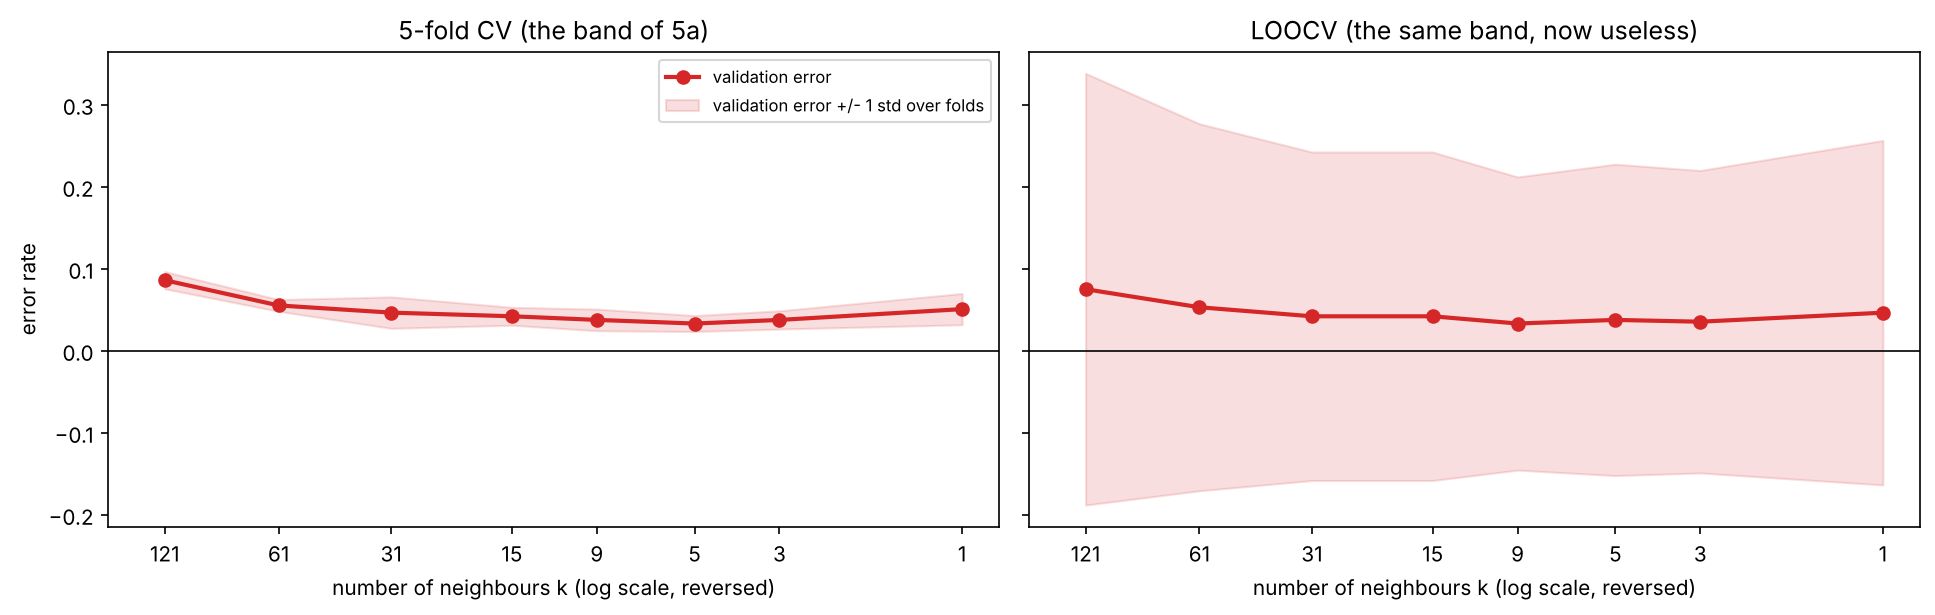

k,1,3,5,9,15,31,61,121
val mean,0.0463,0.0352,0.0374,0.0330,0.0419,0.0419,0.0529,0.0749
val std,0.2100,0.1844,0.1898,0.1787,0.2002,0.2002,0.2238,0.2632


In [ ]:
p = loo_error                                        # the LOOCV error of 5-NN from 1.2
print("distinct values among the 454 fold errors :", np.unique(loo_val))
print(f"std over the 454 LOOCV folds              : {loo_val.std():.4f}")
print(f"sqrt(p * (1 - p)) with p = {p:.4f}          : {np.sqrt(p * (1 - p)):.4f}   (computed from the mean alone)")
print(f"std over folds divided by sqrt(454)       : {loo_val.std() / np.sqrt(n_dev):.4f}")

# the band of Part 5 drawn for LOOCV, next to the band for 5-fold CV
k_small = [1, 3, 5, 9, 15, 31, 61, 121]              # a subset of k_values, to keep the run time short
rows = []                                            # one dictionary per row of the table
for k in k_small:
    _, v = cross_val_errors(make_knn(k), X_dev, y_dev, loo_folds)       # 454 fits for every k
    rows.append({"k": k, "val mean": v.mean(), "val std": v.std()})  # mean and std of 454 fold errors
loo_curve = pd.DataFrame(rows).set_index("k")        # the same columns as knn_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)  # two panels, shared y-axis
for ax, curve, title in zip(axes, [knn_curve.loc[k_small], loo_curve],
                            ["5-fold CV (the band of 5a)", "LOOCV (the same band, now useless)"]):
    ax.plot(k_small, curve["val mean"], "o-", color="tab:red", lw=2, label="validation error")  # the curve
    ax.fill_between(k_small, curve["val mean"] - curve["val std"], curve["val mean"] + curve["val std"],
                    color="tab:red", alpha=0.15, label="validation error +/- 1 std over folds")
    ax.axhline(0, color="black", lw=0.8)                                # an error rate can never go below this
    ax.set_xscale("log")                             # log scale for k
    ax.set_xticks(k_small)                           # a tick at every k we tried
    ax.set_xticklabels(k_small)                      # labelled with the k values themselves
    ax.xaxis.set_minor_locator(plt.NullLocator())                      # hide the unlabelled log-scale ticks
    ax.set_xlim(170, 0.8)                                               # reversed: simple models on the left
    ax.set_xlabel("number of neighbours k (log scale, reversed)")  # x-axis label
    ax.set_title(title)                              # panel title
axes[0].set_ylabel("error rate")                     # y-axis label, left panel only
axes[0].legend(fontsize=8)                           # legend on the left panel
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

loo_curve.T                                          # display, k across the page

**Line by line**

- `np.unique(loo_val)` : the distinct values in the array. It prints `[0. 1.]`: every LOOCV fold error is 0 or 1.
- `loo_val.std()` : the "std over folds" that Part 5 drew as a band, now computed over the 454 LOOCV folds.
- `np.sqrt(p * (1 - p))` : the standard deviation of a variable that is 1 with probability $p$ and 0 otherwise. It
  uses nothing but the mean $p$.
- `loo_val.std() / np.sqrt(n_dev)` : what you would get by turning the band into a "standard error" (as Exercise 5
  does for 5-fold CV).
- `k_small` and the loop : LOOCV for eight values of $k$ (454 fits each), storing the mean and the std over folds,
  the same two columns as `knn_curve`.
- `knn_curve.loc[k_small]` : the 5-fold results of 5a for the same eight values of $k$, selected by their labels.
- `zip(axes, [...], [...])` : the left panel gets the 5-fold curve, the right panel the LOOCV curve, each with its
  own title.
- `ax.fill_between(x, lower, upper, ...)` : shades the band from mean minus std to mean plus std, as in 5a.
- `ax.axhline(0, ...)` : a black line at zero, to show where the band crosses into impossible values.
- `ax.set_xlim(170, 0.8)` : limits in reverse order flip the axis, as in 5a.

**Reading the output.**

- The standard deviation over the 454 LOOCV folds is 0.1898, and $\sqrt{p(1-p)}$ is **exactly the same number**. For
  0/1 fold errors the "std over folds" is a fixed function of the mean, so it contains no information beyond the
  mean itself.
- Left panel: with 5-fold CV the band is narrow (each fold error is an average over about 91 rows) and the shape of
  the curve is visible through it. Right panel: the LOOCV band is about five times wider than the error itself; it
  runs from about $-0.15$ to $+0.23$, goes far below zero, which no error rate can do, and hides every difference
  between the values of $k$.
- The LOOCV curve itself (the red line) is perfectly usable. Its lowest point is at $k = 9$ (0.0330) while 5-fold CV
  chose $k = 5$: another sign of the flat bottom of the U that 5a described.

**Answer.** In $K$-fold CV each fold error is an **average** over many rows, and the spread of those averages says
something about how much an error estimated from one fold wobbles. In LOOCV there is no averaging inside a fold:
each fold error is the 0-1 loss of a single row. Their standard deviation is $\sqrt{p(1-p)}$, which only describes
how a single 0/1 outcome varies; it does not measure how much the **CV estimate** would change with different data.
Drawn as a band it is huge (0.19 around 0.037) and meaningless. Dividing it by $\sqrt{n}$ does not rescue it either:
that formula assumes the 454 terms are independent, but the 454 models share 452 of their 453 training rows, so
their errors are strongly linked. To put an uncertainty on a cross-validation estimate, use repeated $K$-fold
(1.2 and 3d), or the spread of the fold errors of ordinary 5-fold or 10-fold CV, keeping in mind that this too is
only a rough guide (Exercise 5, step 1).

# Exercise 2: Stratification when one class is rare

**Task.**

1. Build a rare-class development set that keeps all benign rows of `X_dev` but only its first 20 malignant rows,
   and shuffle it. What fraction of this new set is malignant?
2. Make 10 plain folds and 10 stratified folds, and print the number of malignant rows in every validation fold.
   Repeat the plain version for 200 seeds and report the average number of folds that contain no malignant row.
3. For 5-NN, compute in every validation fold the error rate and the **recall** of the malignant class. What goes
   wrong with recall in a fold with no malignant rows? How does stratification fix it?
4. Compare the spread (std over 200 shuffles) of the plain and the stratified CV error estimate on the rare-class
   set. Is the difference bigger or smaller than on the original data (Part 4d)?
5. Why does stratification matter more the rarer the class is?

**Concept.** A fold is a small random sample of rows. If a class makes up a fraction $\pi$ of $n$ rows and a fold
holds $m$ rows, the number of rows of that class in the fold is random, with mean $m\pi$ and a standard deviation of
roughly $\sqrt{m \pi (1 - \pi)}$. What matters is the size of that wobble **relative to the mean**:

- original data, 10 folds: about $45 \times 0.372 \approx 17$ malignant rows per fold, give or take about 3;
- rare-class data, 10 folds: about $2$ malignant rows per fold, give or take about 1.3.

A wobble of 3 around 17 is harmless. A wobble of 1.3 around 2 means that folds with 0, 1, 4 or 5 malignant rows are
common. **Recall** of the malignant class is the fraction of truly malignant rows that the model predicts as
malignant,

$$\text{recall} = \frac{\#\{\text{malignant rows predicted malignant}\}}{\#\{\text{malignant rows}\}},$$

and its denominator is exactly the count that wobbles.

## 2.1 The rare-class development set

In [ ]:
rng_ex2 = np.random.default_rng(2)                   # this exercise's own seeded generator (see the introduction)

benign_rows = np.flatnonzero(y_dev == 1)             # positions of all benign tumours in the development set
malignant_rows = np.flatnonzero(y_dev == 0)          # positions of all malignant tumours
keep = np.concatenate([benign_rows, malignant_rows[:20]])   # every benign row + only the first 20 malignant rows
keep = rng_ex2.permutation(keep)                     # shuffle, so the new set is not sorted by class

X_rare, y_rare = X_dev[keep], y_dev[keep]            # the rare-class development set
n_rare = len(y_rare)                                 # its number of rows
n_mal = int(np.sum(y_rare == 0))                     # number of malignant rows (20)

print("rows                :", n_rare)
print("class counts        :", {str(name): int(count) for name, count in zip(class_names_bc, np.bincount(y_rare))})
print(f"fraction malignant  : {np.mean(y_rare == 0):.4f}   (full development set: {np.mean(y_dev == 0):.4f})")
print(f"malignant rows per fold if 10 folds were perfectly balanced: {n_mal / 10:.1f}")

rows                : 305
class counts        : {'malignant': 20, 'benign': 285}
fraction malignant  : 0.0656   (full development set: 0.3722)
malignant rows per fold if 10 folds were perfectly balanced: 2.0


**Line by line**

- `rng_ex2 = np.random.default_rng(2)` : a new generator with its own seed. The exercise says `rng.permutation`; using
  a dedicated generator does the same job and makes the result independent of what was run before.
- `np.flatnonzero(y_dev == 1)` : the positions in `y_dev` where the label is 1 (benign). Likewise for 0 (malignant).
- `malignant_rows[:20]` : the **first 20** malignant positions, as the exercise specifies.
- `np.concatenate([...])` : one array of row numbers: 285 benign followed by 20 malignant. That order is sorted by
  class, which is a trap for any procedure that takes "the first so many rows" (section 0c), so:
- `rng_ex2.permutation(keep)` : a shuffled copy of the row numbers.
- `X_dev[keep], y_dev[keep]` : the selected rows, in the shuffled order, for both `X` and `y`.
- `np.sum(y_rare == 0)` : counts the `True` values, i.e. the malignant rows. `int(...)` makes it a plain number.
- `{str(name): int(count) for name, count in zip(class_names_bc, np.bincount(y_rare))}` : a dictionary
  comprehension that pairs each class name with its count. `zip` walks through the two names and the two counts
  together; `str(...)` and `int(...)` turn NumPy's string and integer types into plain Python ones, so the
  dictionary prints as `{'malignant': 20, 'benign': 285}` instead of showing the NumPy type names.

**Reading the output.** The new set has 305 rows: 285 benign and 20 malignant. The malignant fraction is
$20/305 = 0.0656$, about 6.6%, down from 37.2%. With 10 folds a perfectly balanced fold would hold only 2 malignant
rows.

## 2.2 Malignant rows per fold, and how often a fold has none

rows per validation fold          : [31, 31, 31, 31, 31, 30, 30, 30, 30, 30]
malignant rows per plain fold      : [2, 1, 2, 1, 2, 1, 3, 5, 3, 0]
malignant rows per stratified fold : [2, 2, 2, 2, 2, 2, 2, 2, 2, 2]



over 200 seeds, plain 10-fold:
  average number of folds with NO malignant row : 1.125
  fraction of splits with at least one such fold : 77.5%
  splits with 0, 1, 2, ... empty folds          : [45 98 46  9  2]
over 200 seeds, stratified 10-fold: largest number of empty folds = 0
  expected number of empty folds, from theory    : 1.132


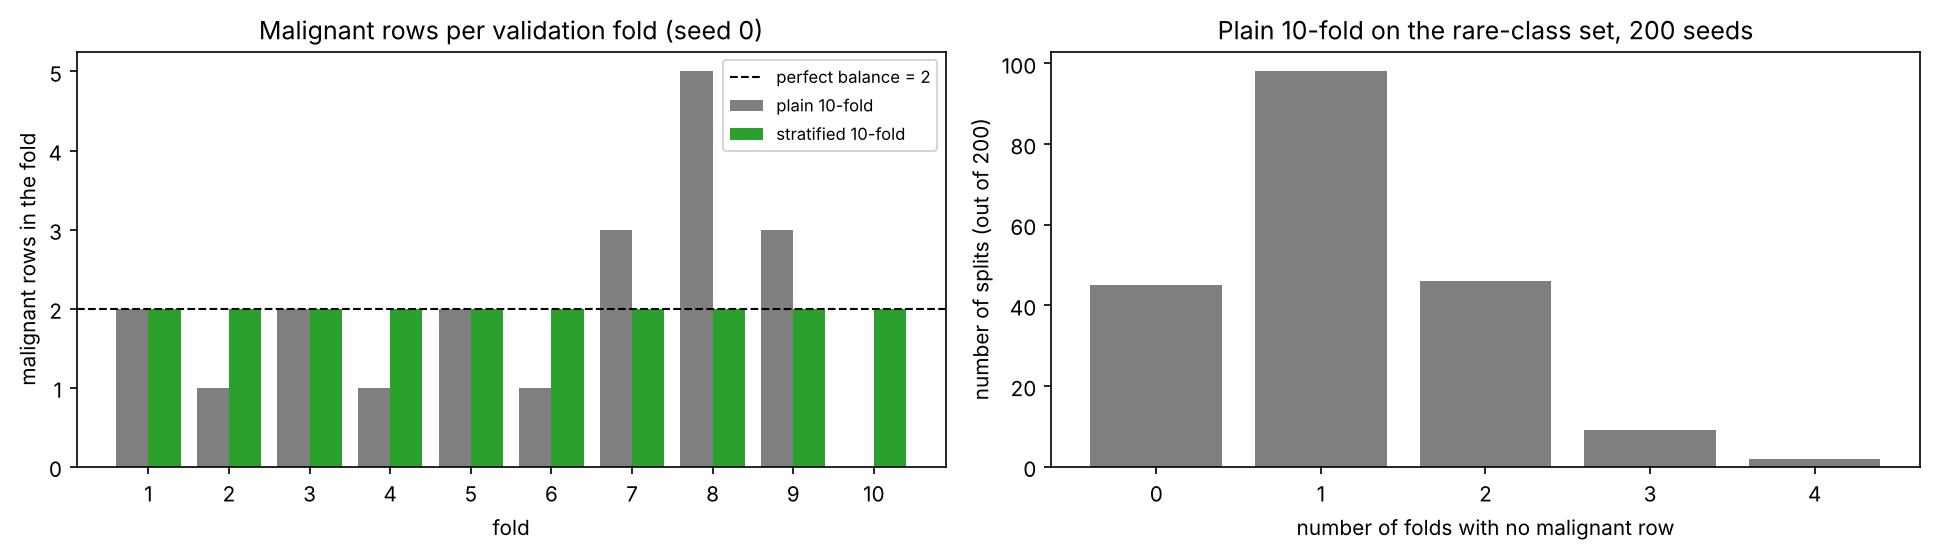

In [ ]:
plain_rare = kfold_indices(n_rare, 10, seed=0)                     # 10 plain (shuffled) folds
strat_rare = stratified_kfold_indices(y_rare, 10, seed=0)          # 10 stratified folds

count_plain = [int(np.sum(y_rare[va] == 0)) for _, va in plain_rare]   # malignant rows in each validation fold
count_strat = [int(np.sum(y_rare[va] == 0)) for _, va in strat_rare]  # the same, stratified
print("rows per validation fold          :", [len(va) for _, va in plain_rare])
print("malignant rows per plain fold      :", count_plain)
print("malignant rows per stratified fold :", count_strat)

N_SEEDS = 200                                        # number of different shuffles
empty_plain = np.empty(N_SEEDS, dtype=int)           # number of folds with no malignant row, per seed
empty_strat = np.empty(N_SEEDS, dtype=int)           # the same count, stratified
for s in range(N_SEEDS):
    folds_p = kfold_indices(n_rare, 10, seed=s)      # plain folds for seed s
    folds_s = stratified_kfold_indices(y_rare, 10, seed=s)  # stratified folds for seed s
    empty_plain[s] = sum(np.sum(y_rare[va] == 0) == 0 for _, va in folds_p)   # count the empty folds
    empty_strat[s] = sum(np.sum(y_rare[va] == 0) == 0 for _, va in folds_s)  # count the empty folds

print(f"\nover {N_SEEDS} seeds, plain 10-fold:")
print(f"  average number of folds with NO malignant row : {empty_plain.mean():.3f}")
print(f"  fraction of splits with at least one such fold : {np.mean(empty_plain > 0):.1%}")
print( "  splits with 0, 1, 2, ... empty folds          :", np.bincount(empty_plain))
print(f"over {N_SEEDS} seeds, stratified 10-fold: largest number of empty folds = {empty_strat.max()}")

# the same average from probability theory
n_ben = n_rare - n_mal                               # 285 benign rows


def prob_no_malignant(m):
    '''Probability that m rows drawn at random, without replacement, contain no malignant row.'''
    i = np.arange(m)                                 # 0, 1, ..., m-1
    return np.prod((n_ben - i) / (n_rare - i))       # every draw must be benign: 285/305 * 284/304 * ...


fold_sizes_rare = [len(va) for _, va in plain_rare]  # 31 or 30 rows per fold
print(f"  expected number of empty folds, from theory    : {sum(prob_no_malignant(m) for m in fold_sizes_rare):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))    # two panels side by side
pos = np.arange(1, 11)                               # x positions 1..10, one per fold
axes[0].bar(pos - 0.2, count_plain, width=0.4, color="tab:grey", label="plain 10-fold")  # shifted left
axes[0].bar(pos + 0.2, count_strat, width=0.4, color="tab:green", label="stratified 10-fold")  # right
axes[0].axhline(n_mal / 10, color="black", ls="dashed", lw=1, label="perfect balance = 2")  # the target
axes[0].set_xticks(pos)                              # one tick per fold
axes[0].set_xlabel("fold")                           # x-axis label
axes[0].set_ylabel("malignant rows in the fold")     # y-axis label
axes[0].set_title("Malignant rows per validation fold (seed 0)")  # panel title
axes[0].legend(fontsize=8)                           # legend on the left panel
counts = np.bincount(empty_plain)                    # splits with 0, 1, 2, ... empty folds
axes[1].bar(np.arange(len(counts)), counts, color="tab:grey")  # one bar per number of empty folds
axes[1].set_xticks(np.arange(len(counts)))           # one tick per bar
axes[1].set_xlabel("number of folds with no malignant row")  # x-axis label
axes[1].set_ylabel("number of splits (out of 200)")  # y-axis label
axes[1].set_title("Plain 10-fold on the rare-class set, 200 seeds")  # panel title
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

**Line by line**

- `kfold_indices(n_rare, 10, seed=0)` and `stratified_kfold_indices(y_rare, 10, seed=0)` : our two fold makers from
  Parts 3 and 4. Plain folds ignore the labels; stratified folds use them.
- `[int(np.sum(y_rare[va] == 0)) for _, va in plain_rare]` : for every fold, take the labels of its validation rows
  and count the malignant ones. `_` receives the training rows, which are not needed here.
- `empty_plain = np.empty(N_SEEDS, dtype=int)` : room for 200 whole numbers.
- `np.sum(y_rare[va] == 0) == 0` : `True` when a fold has no malignant row. Python's built-in `sum` over the ten
  folds adds up these `True`/`False` values (`True` counts as 1), giving the number of empty folds in one split.
- `empty_plain.mean()` : the average number of empty folds per split.
- `np.mean(empty_plain > 0)` : the fraction of splits with at least one empty fold. The format `:.1%` prints a
  fraction as a percentage with one decimal.
- `np.bincount(empty_plain)` : how many splits had 0, 1, 2, ... empty folds.
- `prob_no_malignant(m)` : a fold of $m$ rows contains no malignant row only if every one of its rows is benign. The
  first row is benign with probability $285/305$, the second (given the first) with $284/304$, and so on, so the
  probability is the product $\prod_{i=0}^{m-1} \frac{285 - i}{305 - i}$. `np.arange(m)` gives all the $i$ at once and
  `np.prod` multiplies the $m$ fractions.
- `sum(prob_no_malignant(m) for m in fold_sizes_rare)` : the expected number of empty folds is the sum of the
  probabilities over the ten folds (an average of a sum is the sum of the averages).
- The figure: on the left, the counts of this one split side by side (same bar recipe as 4d); on the right, a bar
  for every possible number of empty folds, with its frequency over the 200 seeds.

**Reading the output.**

- The plain folds of seed 0 hold 2, 1, 2, 1, 2, 1, 3, **5**, 3 and **0** malignant rows. Fold 8 has five times as
  many as fold 2, and fold 10 has none at all. The stratified folds hold exactly 2 each.
- Over 200 seeds, plain 10-fold produces on average **1.125 folds without a single malignant row**, and 77.5% of all
  splits contain at least one such fold. Some splits have 3 or even 4 of them. Stratified folds never do: the
  largest number of empty folds over all 200 seeds is 0.
- Probability theory predicts 1.13 empty folds per split, in close agreement with the simulation. So this is not bad
  luck with a few seeds: it is what plain $K$-fold does to a class with 20 members.

## 2.3 Error rate and malignant recall in every fold

In [ ]:
def recall_malignant(y_true, y_pred):
    '''Recall of the malignant class (label 0): the fraction of truly malignant rows predicted malignant.

    Returns np.nan when y_true contains no malignant row, because 0 / 0 is undefined.
    '''
    is_malignant = (y_true == 0)                     # True for the truly malignant rows
    if is_malignant.sum() == 0:                      # this fold has no malignant row at all
        return np.nan                                # "not a number": recall cannot be computed
    return np.mean(y_pred[is_malignant] == 0)        # fraction of them that were predicted malignant


def fold_error_and_recall(model, X, y, folds):
    '''Like cross_val_errors, but reports for every fold the error rate AND the malignant recall.

    returns : (table with one row per fold, out-of-fold prediction for every row)
    '''
    rows = []                                        # one dictionary per fold
    oof_pred = np.empty(len(y), dtype=int)           # "out-of-fold" prediction for every row
    for j, (tr, va) in enumerate(folds):
        fitted = clone(model).fit(X[tr], y[tr])      # a fresh model, trained on the other folds
        pred = fitted.predict(X[va])                 # predictions for this validation fold
        oof_pred[va] = pred                          # store them at the positions of the fold's rows
        rows.append({"fold": j + 1, "rows": len(va), "malignant rows": int(np.sum(y[va] == 0)),  # one row per fold
                     "error rate": error_rate(y[va], pred),
                     "recall (malignant)": recall_malignant(y[va], pred)})
    return pd.DataFrame(rows).set_index("fold"), oof_pred


table_plain, oof_plain = fold_error_and_recall(make_knn(5), X_rare, y_rare, plain_rare)  # plain folds
table_strat, oof_strat = fold_error_and_recall(make_knn(5), X_rare, y_rare, strat_rare)  # stratified folds

display(pd.concat({"plain folds": table_plain, "stratified folds": table_strat}, axis=1))  # side by side

pd.DataFrame({                                       # a table, displayed as the last line
    "CV error (mean of fold errors)": [table_plain["error rate"].mean(), table_strat["error rate"].mean()],
    "mean of fold recalls, NumPy": [table_plain["recall (malignant)"].to_numpy().mean(),
                                    table_strat["recall (malignant)"].to_numpy().mean()],
    "mean of fold recalls, pandas": [table_plain["recall (malignant)"].mean(),
                                     table_strat["recall (malignant)"].mean()],
    "pooled recall (all 20 rows)": [recall_malignant(y_rare, oof_plain), recall_malignant(y_rare, oof_strat)],
}, index=["plain folds", "stratified folds"])

plain folds                                               \
            rows malignant rows error rate recall (malignant)   
fold                                                            
1             31              2     0.0000             1.0000   
2             31              1     0.0000             1.0000   
3             31              2     0.0000             1.0000   
4             31              1     0.0000             1.0000   
5             31              2     0.0323             0.5000   
6             30              1     0.0000             1.0000   
7             30              3     0.0000             1.0000   
8             30              5     0.1000             0.4000   
9             30              3     0.0333             0.6667   
10            30              0     0.0000                NaN   

     stratified folds                                               
                 rows malignant rows error rate recall (malignant)  
fold                                                                
1                  31              2     0.0000                1.0  
2                  31              2     0.0000                1.0  
3                  31              2     0.0000                1.0  
4                  31              2     0.0000                1.0  
5                  31              2     0.0000                1.0  
6                  30              2     0.0667                0.0  
7                  30              2     0.0000                1.0  
8                  30              2     0.0333                0.5  
9                  30              2     0.0000                1.0  
10                 30              2     0.0333                0.5

,CV error (mean of fold errors),"mean of fold recalls, NumPy","mean of fold recalls, pandas",pooled recall (all 20 rows)
plain folds,0.0166,NaN,0.8407,0.75
stratified folds,0.0133,0.8,0.8000,0.80


**Line by line**

- `recall_malignant(y_true, y_pred)` :
  - `is_malignant = (y_true == 0)` : a boolean mask of the truly malignant rows (label 0, remember the coding).
  - `if is_malignant.sum() == 0: return np.nan` : if there are no malignant rows, recall would be $0/0$. NumPy would
    return `nan` anyway, but with a warning; returning `np.nan` ourselves makes the special case explicit.
  - `y_pred[is_malignant] == 0` : the predictions for the malignant rows only, compared with "malignant". Its mean
    is the fraction of malignant rows that were caught.
- `fold_error_and_recall(model, X, y, folds)` : the loop of `cross_val_errors`, with three changes:
  - it records the number of malignant rows, the error rate and the recall of each fold in a table;
  - `oof_pred[va] = pred` writes each fold's predictions into the positions of its rows. Because every row is in
    exactly one validation fold, after the loop `oof_pred` holds one **out-of-fold** prediction for every row, each
    made by a model that never saw that row;
  - it skips the training error, which this exercise does not need.
- `pd.concat({...}, axis=1)` : puts the two fold tables side by side under the headings "plain folds" and
  "stratified folds". `display(...)` shows a table in the middle of a cell (normally only the last line is shown).
- The summary table compares four numbers for each kind of fold:
  - `table_plain["error rate"].mean()` : the CV error, the average of the ten fold errors.
  - `.to_numpy().mean()` : the NumPy average of the ten fold recalls. NumPy follows the rule "anything combined with
    `nan` is `nan`".
  - `table_plain["recall (malignant)"].mean()` : the **pandas** average of the same ten numbers. pandas silently
    **skips** `nan` values, so it averages over the folds that have a recall.
  - `recall_malignant(y_rare, oof_plain)` : the **pooled** recall, computed once from the out-of-fold predictions of
    all 20 malignant rows together.

**Reading the output.**

- **Plain folds.** Fold 10 has no malignant rows, so its recall is `NaN`. The NumPy average of the fold recalls is
  therefore `NaN` too, while pandas quietly reports 0.8407, an average over 9 folds that hides the problem. The
  folds with one malignant row (2, 4 and 6) can only give a recall of 0 or 1, so each of them swings the average by a
  tenth. Fold 8 holds five malignant rows and the model catches only two of them (recall 0.4), yet in the average of
  fold recalls it counts no more than fold 2 with its single row. As a result the average of fold recalls (0.84)
  disagrees with the pooled recall (0.75: 15 of the 20 malignant tumours are caught).
- **Stratified folds.** Every fold has exactly 2 malignant rows, so every recall is defined (0, 0.5 or 1), the NumPy
  and pandas averages agree, and the average of the fold recalls is **exactly** the pooled recall, 0.80 (16 of 20).
  When every fold has the same number of malignant rows, averaging per fold and pooling are the same calculation.
- The CV error rates (0.0166 and 0.0133) are both small, because 93% of the rows are benign and easy. An error rate
  near 0.015 says very little about how well the **rare** class is found; that is why recall is the number to watch
  here.

**Answer.** In a fold without malignant rows the recall is $0/0$: undefined. Depending on the software it becomes
`NaN` and poisons the average, or it is silently dropped and the average is taken over fewer folds without anyone
noticing. Folds with one or two malignant rows give recalls that can only be 0, 0.5 or 1, and averaging such folds
with equal weight gives the same importance to one row in one fold as to five rows in another. Stratification fixes
this by giving every fold the same number of malignant rows (here 2): the recall is defined in every fold, and the
average of the fold recalls equals the pooled recall. For a rare class, a good habit (with or without
stratification) is to compute rare-class measures such as recall **once**, from the pooled out-of-fold predictions,
as in the last column.

## 2.4 Spread over 200 shuffles: rare-class set versus original data

The exercise asks for the standard deviation of the CV error estimate over 200 shuffles. Part 4d looked at a second
kind of spread, the differences between the folds **within** one split, and step 3 showed that the recall is the
number that suffers most. So the function below records all of these for every shuffle, for plain and for
stratified 10-fold, and we run it on both datasets.

In [ ]:
def compare_schemes(X, y, n_seeds=200, n_folds=10):
    '''Plain and stratified K-fold CV of 5-NN over n_seeds shuffles; summarise how much the results vary.'''
    summary = {}                                     # maps each scheme to its eight results
    for scheme in ["plain", "stratified"]:
        cv_err, fold_spread, fold_recall, pooled_recall, nan_folds = [], [], [], [], []  # one entry per shuffle
        for s in range(n_seeds):
            if scheme == "plain":
                folds = kfold_indices(len(y), n_folds, seed=s)  # plain folds
            else:
                folds = stratified_kfold_indices(y, n_folds, seed=s)  # stratified folds
            table, oof = fold_error_and_recall(make_knn(5), X, y, folds)  # one complete CV run
            errors = table["error rate"].to_numpy()                   # the fold errors of this split
            recalls = table["recall (malignant)"].to_numpy()          # the fold recalls (may contain nan)
            cv_err.append(errors.mean())                              # the CV error estimate
            fold_spread.append(errors.std())                          # spread of the folds WITHIN this split
            fold_recall.append(np.nanmean(recalls))                   # mean of fold recalls, nan folds skipped
            pooled_recall.append(recall_malignant(y, oof))            # recall from all out-of-fold predictions
            nan_folds.append(np.isnan(recalls).sum())                 # folds where recall was undefined
        summary[scheme] = {                          # eight summary numbers for this scheme
            "mean CV error": np.mean(cv_err),
            "std of CV error over shuffles": np.std(cv_err),
            "average std of the fold errors within a split": np.mean(fold_spread),
            "mean of fold recalls": np.mean(fold_recall),
            "std of mean fold recall over shuffles": np.std(fold_recall),
            "mean pooled recall": np.mean(pooled_recall),
            "std of pooled recall over shuffles": np.std(pooled_recall),
            "average folds with undefined recall": np.mean(nan_folds),
        }
    return pd.DataFrame(summary)


spread_table = pd.concat({"rare-class set (6.6% malignant)": compare_schemes(X_rare, y_rare),
                          "original dev set (37.2% malignant)": compare_schemes(X_dev, y_dev)}, axis=1)
spread_table                                         # display the table

rare-class set (6.6% malignant)  \
                                                                        plain   
mean CV error                                                          0.0162   
std of CV error over shuffles                                          0.0028   
average std of the fold errors within a split                          0.0226   
mean of fold recalls                                                   0.7709   
std of mean fold recall over shuffles                                  0.0591   
mean pooled recall                                                     0.7530   
std of pooled recall over shuffles                                     0.0423   
average folds with undefined recall                                    1.1250   

                                                          \
                                              stratified   
mean CV error                                     0.0154   
std of CV error over shuffles                     0.0026   
average std of the fold errors within a split     0.0191   
mean of fold recalls                              0.7645   
std of mean fold recall over shuffles             0.0399   
mean pooled recall                                0.7645   
std of pooled recall over shuffles                0.0399   
average folds with undefined recall               0.0000   

                                              original dev set (37.2% malignant)  \
                                                                           plain   
mean CV error                                                             0.0381   
std of CV error over shuffles                                             0.0025   
average std of the fold errors within a split                             0.0265   
mean of fold recalls                                                      0.9135   
std of mean fold recall over shuffles                                     0.0062   
mean pooled recall                                                        0.9134   
std of pooled recall over shuffles                                        0.0046   
average folds with undefined recall                                       0.0000   

                                                          
                                              stratified  
mean CV error                                     0.0382  
std of CV error over shuffles                     0.0025  
average std of the fold errors within a split     0.0259  
mean of fold recalls                              0.9132  
std of mean fold recall over shuffles             0.0053  
mean pooled recall                                0.9132  
std of pooled recall over shuffles                0.0053  
average folds with undefined recall               0.0000

**Line by line**

- `def compare_schemes(X, y, n_seeds=200, n_folds=10):` : one function, so the same experiment runs on both
  datasets. The default arguments are the values of the exercise.
- `for scheme in ["plain", "stratified"]:` : the outer loop runs the experiment twice, once per kind of fold.
- Five empty lists collect one number per shuffle.
- `if scheme == "plain": ... else: ...` : picks the fold maker. Both receive the same seed `s`.
- `fold_error_and_recall(make_knn(5), X, y, folds)` : the function of step 3.
- `errors.mean()` : the CV error estimate of this shuffle; its spread over the 200 shuffles is what the exercise asks
  for.
- `errors.std()` : how different the ten folds of **this** split are from each other (the view of Part 4d).
- `np.nanmean(recalls)` : the mean of the fold recalls, skipping undefined folds (the pandas behaviour of step 3).
- `np.isnan(recalls).sum()` : how many folds of this split had an undefined recall.
- `summary[scheme] = {...}` : eight summary numbers per scheme. `pd.DataFrame(summary)` turns the dictionary into a
  table with one column per scheme.
- `pd.concat({...: ..., ...: ...}, axis=1)` : places the two datasets' tables side by side under their names.

**Reading the output.** Compare the "plain" and "stratified" columns within each dataset.

- **Std of the CV error over shuffles** (the number the exercise asks for). On the rare-class set it is 0.0028 for
  plain and 0.0026 for stratified folds, about 6% smaller with stratification. On the original data it is 0.0025 for
  both. So the difference is a little **bigger** on the rare-class set, but small on both: a standard deviation
  estimated from 200 repeats is itself uncertain by about 5%, so even the 6% is hardly more than noise.
- **Average std of the fold errors within a split.** On the rare-class set stratification makes the ten folds more
  alike (0.0226 down to 0.0191, about 15% smaller); on the original data the change is negligible (0.0265 and
  0.0259).
- **Recall.** This is where the rare class shows the real benefit. With plain folds the mean of fold recalls varies
  from shuffle to shuffle with a standard deviation of 0.059; with stratified folds it is 0.040, a third less. Plain
  splits have on average 1.1 folds with an undefined recall; stratified splits have none. On the original data the
  recall numbers barely differ between the two schemes.
- **A pessimistic bias in plain folds.** The pooled recall averages 0.753 with plain folds and 0.765 with stratified
  folds. When a plain validation fold happens to hold 4 or 5 of the 20 malignant rows, its training set keeps only 15
  or 16 of them, and the model is worse at recognising malignant tumours. With stratification every training set
  keeps exactly 18.

**Answer.** Measured by the overall error rate, the spread over 200 shuffles is nearly the same with and without
stratification on **both** datasets; the difference is somewhat bigger on the rare-class set (about 6% against
none), but small in both cases. The reason is that in both schemes every row is predicted exactly once by a model
trained on 90% of the rows, so the CV error is essentially "total mistakes divided by $n$", and stratification only
moves a malignant row or two between training sets. The benefit of stratification on the rare-class set shows up
instead in everything that concerns the rare class: the folds are more alike, the recall is never undefined, its
estimate is a third less noisy, and it is no longer pulled down by training sets that lost part of the rare class.
On the original data, with 37% malignant, none of these effects is visible, which matches the conclusion of 4d that
stratification was "a modest improvement" there.

## 2.5 Why stratification matters more the rarer the class is

**Answer.** The number of rare-class rows that land in a random fold fluctuates by roughly the square root of its
expected value, so the **relative** fluctuation grows as the expected count shrinks: about 3 around 17 (18%) for
the original data, but about 1.3 around 2 (65%) for the rare-class set. With a rare class, plain folds therefore
regularly contain no rare rows at all (on average 1.1 of 10 folds here), which makes any measure about that class,
such as recall, undefined or extremely noisy, and at the same time leaves the matching training sets short of the
few rare examples there are. Stratification removes this fluctuation by fixing the count in every fold, which is
irrelevant when the class is common and essential when it is rare.

# Exercise 3: Model selection for regression, end to end

**Task.** Repeat the whole protocol of Part 7 on the Diabetes data.

1. Build a candidate list with three families: `DecisionTreeRegressor` with `max_depth` from 1 to 8;
   `KNeighborsRegressor` in a pipeline with a `StandardScaler`, with $k \in \{1, 3, 5, 10, 20, 40, 80\}$; and ridge
   regression (`Ridge`) with `alpha` in `np.logspace(-3, 3, 7)`.
2. Evaluate every candidate with `cross_val_errors(..., folds_db, error_fn=mse)` on the development set only. Show the
   ten best and the best of each family, and compare them with the baseline of 5c.
3. Draw learning curves for the best candidate of each family. For which family would more data help most?
4. Refit the winner on all of `Xr_dev` and evaluate it **once** on `Xr_test`. Report the test MSE, its coefficient of
   determination $R^2 = 1 - \text{MSE}/\text{Var}(y_{\text{test}})$, and compare with the winner's CV error.
5. Could a regression problem be stratified? Cut `yr_dev` into 5 groups by its quantiles, pass the group numbers to
   `stratified_kfold_indices`, and check whether it makes the CV estimate less noisy over 100 shuffles.

**Concept.** Nothing in the protocol of 7a was specific to classification. The six rules are the same; only the
error measure changes, from the error rate to the **mean squared error**. The three families have three different
complexity knobs:

| family | how it predicts | hyper-parameter | simple end | complex end |
|---|---|---|---|---|
| regression tree (5c) | average target of the training rows in the same leaf | `max_depth` | shallow | deep |
| k-NN regression | average target of the $k$ nearest training rows | $k$ | large $k$ | small $k$ |
| ridge regression (Practical 1) | linear function $\hat y = w_0 + w^\top x$, with weights shrunk by the penalty $\alpha \lVert w \rVert^2$ | `alpha` ($\lambda$ of Practical 1) | large $\alpha$ | small $\alpha$ |

The **coefficient of determination** compares a model's MSE with the MSE of the best constant prediction, which is
the variance of the target:

$$R^2 = 1 - \frac{\text{MSE}}{\text{Var}(y)}.$$

$R^2 = 0$ means "no better than predicting the average", $R^2 = 1$ means perfect predictions, and $R^2 < 0$ means
worse than the average.

## 3.1 The candidate list

In [ ]:
from sklearn.neighbors import KNeighborsRegressor    # k-NN for regression: average target of the k nearest rows
from sklearn.linear_model import Ridge               # ridge regression: least squares plus the penalty alpha * ||w||^2

candidates_r = []                                    # list of (family, hyper-parameter name, value, untrained model)
for D in range(1, 9):                                # tree depths 1, 2, ..., 8
    candidates_r.append(("decision tree", "max_depth", D,
                         DecisionTreeRegressor(max_depth=D, random_state=0)))
for k in [1, 3, 5, 10, 20, 40, 80]:                  # numbers of neighbours
    candidates_r.append(("k-NN", "k", k,
                         make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))))
for alpha in np.logspace(-3, 3, 7):                  # penalty strengths 0.001, 0.01, ..., 1000
    candidates_r.append(("ridge", "alpha", alpha,
                         make_pipeline(StandardScaler(), Ridge(alpha=alpha))))

print("number of candidates :", len(candidates_r))
print("alpha values         :", np.logspace(-3, 3, 7))

number of candidates : 22
alpha values         : [   0.001    0.01     0.1      1.      10.     100.    1000.   ]


**Line by line**

- `from sklearn.neighbors import KNeighborsRegressor` : the regression version of k-NN. It finds the $k$ nearest
  training rows exactly like the classifier, but instead of a majority vote it predicts the **average** of their
  targets.
- `from sklearn.linear_model import Ridge` : least-squares linear regression with the ridge penalty of Practical 1.
  scikit-learn calls the penalty strength `alpha`; it is the $\lambda$ of Practical 1.
- `candidates_r = []` : the same format as `candidates` in 7a, a list of four-item tuples.
- `for D in range(1, 9):` : `range(1, 9)` gives 1 to 8 (the end value is not included).
- `DecisionTreeRegressor(max_depth=D, random_state=0)` : exactly the tree of 5c. It is **not** put behind a scaler:
  a tree only asks "is this feature above a threshold?", and rescaling a feature moves the threshold with it, so
  trees do not need scaling. Keeping the tree exactly as in 5c also lets us check our numbers against `tree_curve`.
- `make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))` : scaler first, as the exercise asks, so
  that distances are measured on a common scale (section 0c).
- `np.logspace(-3, 3, 7)` : seven numbers spaced evenly on a log scale, from $10^{-3}$ to $10^{3}$, i.e. 0.001, 0.01,
  0.1, 1, 10, 100, 1000. A penalty strength acts multiplicatively, so its values are tried in factors of 10, as in
  Practical 1 and for $C$ in 7a.
- `make_pipeline(StandardScaler(), Ridge(alpha=alpha))` : ridge is put behind a scaler too, as every candidate in
  Part 7 was. For ridge this is not just tidiness: the penalty $\alpha \lVert w \rVert^2$ treats all weights alike,
  so the features must be on a common scale for one value of $\alpha$ to mean the same for each of them. The short
  check after step 2 shows what happens without the scaler.

**Reading the output.** 22 candidates: 8 trees, 7 k-NN models and 7 ridge models.

## 3.2 Cross-validated MSE of every candidate (development set only)

In [ ]:
rows = []                                   # one dictionary per row of the table
for family, hp, value, model in candidates_r:
    tr_e, va_e = cross_val_errors(model, Xr_dev, yr_dev, folds_db, error_fn=mse)   # the 5 folds of 5c
    rows.append({"model": family, "setting": f"{hp} = {value:g}",  # one row per candidate
                 "train MSE": tr_e.mean(), "CV MSE": va_e.mean(), "std over folds": va_e.std()})
cv_table_r = pd.DataFrame(rows)                      # one row per candidate

print("tree rows identical to tree_curve of 5c:",
      np.allclose(cv_table_r.loc[0:7, "CV MSE"].to_numpy(), tree_curve.loc[1:8, "val MSE"].to_numpy()))

best_r_idx = int(cv_table_r["CV MSE"].idxmin())      # position of the overall winner
family_r, hp_r, value_r, model_r = candidates_r[best_r_idx]  # unpack the winner
print(f"CV winner: {family_r} with {hp_r} = {value_r:g},   CV MSE = {cv_table_r.loc[best_r_idx, 'CV MSE']:.1f}")
print(f"baseline (always predict the training mean, 5c): CV MSE = {baseline:.1f}\n")

best_of_family_r = cv_table_r.loc[cv_table_r.groupby("model")["CV MSE"].idxmin()].copy()   # best row per family
best_of_family_r["fraction of baseline MSE removed"] = 1 - best_of_family_r["CV MSE"] / baseline
print("best setting of each family:")
print(best_of_family_r.round(3).to_string(index=False))
print("\nthe ten best candidates overall:")
cv_table_r.sort_values("CV MSE", kind="stable").head(10)  # the ten best, best first

tree rows identical to tree_curve of 5c: True
CV winner: ridge with alpha = 10,   CV MSE = 3075.2
baseline (always predict the training mean, 5c): CV MSE = 5943.0

best setting of each family:
        model       setting  train MSE   CV MSE  std over folds  fraction of baseline MSE removed
decision tree max_depth = 2   3328.312 4091.753         569.738                             0.311
         k-NN        k = 20   2998.547 3391.252         255.699                             0.429
        ridge    alpha = 10   2897.939 3075.212         297.123                             0.483

the ten best candidates overall:


,model,setting,train MSE,CV MSE,std over folds
19,ridge,alpha = 10,2897.9390,3075.2123,297.1232
18,ridge,alpha = 1,2881.8572,3089.3290,304.7400
17,ridge,alpha = 0.1,2879.4190,3097.2413,307.3952
16,ridge,alpha = 0.01,2879.3704,3098.6397,307.8217
15,ridge,alpha = 0.001,2879.3699,3098.7901,307.8672
20,ridge,alpha = 100,3007.3571,3135.0128,293.0282
12,k-NN,k = 20,2998.5467,3391.2517,255.6987
11,k-NN,k = 10,2790.0587,3439.4040,397.2432
13,k-NN,k = 40,3282.8552,3474.4597,288.1362
10,k-NN,k = 5,2471.3171,3736.9741,484.2428


**Line by line**

- The loop is the loop of 7c with two changes: the regression data `Xr_dev, yr_dev`, and `error_fn=mse`. The folds
  are `folds_db`, the plain 5-fold split of the 353 development patients from 5c, so every candidate is judged on
  exactly the same folds.
- `f"{hp} = {value:g}"` : the format `g` prints a number in its shortest natural form, so `alpha = 10` instead of
  `alpha = 10.0` and `alpha = 0.001` instead of `alpha = 1e-03`.
- `np.allclose(cv_table_r.loc[0:7, ...].to_numpy(), tree_curve.loc[1:8, ...].to_numpy())` : the first 8 rows of our
  table are the trees of depth 1 to 8, which 5c already evaluated on the same folds. `.loc[0:7]` selects by label and
  **includes** both ends, so it is 8 rows. `.to_numpy()` is needed because the two tables have different index
  labels (0 to 7 against 1 to 8): pandas would otherwise try to line the values up by label and find no matches.
- `cv_table_r["CV MSE"].idxmin()` : the row with the smallest CV MSE. The ridge values are all different, so there is
  no tie to worry about here.
- `cv_table_r.groupby("model")["CV MSE"].idxmin()` : the best row of each family, as in 7c. `.copy()` makes an
  independent table, so that adding a column to it does not touch `cv_table_r`.
- `1 - CV MSE / baseline` : the fraction of the baseline's error that the model removes. It is a cross-validated
  analogue of $R^2$: 0 means no better than predicting the training mean.
- `.round(3).to_string(index=False)` : prints the small table without its row numbers.
- `sort_values("CV MSE", kind="stable").head(10)` : the ten best candidates, best first.

**Reading the output.**

- The tree rows agree with 5c (the check prints `True`), so the regression loop and the folds are the same as in the
  practical.
- **Ridge regression wins**, with $\alpha = 10$ and a CV MSE of 3075.2. In fact ridge occupies the **first six
  places**: every $\alpha$ from 0.001 to 100 gives a CV MSE between 3075 and 3135. With 10 standardised features and
  about 282 training rows per fold, the penalty only starts to matter once $\alpha$ is comparable to the number of
  rows; below that, all the ridge models are practically ordinary least squares. At $\alpha = 1000$ the penalty
  shrinks the weights far too much and the CV MSE jumps to 4131: underfitting.
- **Best of each family:** ridge 3075 (removes 48% of the baseline error), k-NN with $k = 20$ at 3391 (43%), and the
  tree of depth 2 at 4092 (31%). All three beat the baseline of 5943.
- The complexity pattern of Part 5 appears in every family. k-NN with $k = 1$ has a training MSE of 0 and a CV MSE of
  6627, **worse than the baseline**: pure memorisation. The tree of depth 8 has a training MSE of 669 and a CV MSE of
  6013, also worse than the baseline. Ridge, a model with only 11 parameters, has training and CV MSE close together
  (2898 and 3075 at $\alpha = 10$).
- The data favour the simplest family. Disease progression depends on these features in a way that is roughly
  linear, and the noise is large, so a smooth model with few parameters generalises best.

**A short check: why ridge sits behind a scaler.** The Diabetes columns were already rescaled by the creators of
the dataset, but not to standard deviation 1. The cell below compares ridge with and without the scaler.

In [ ]:
print("standard deviation of each Diabetes column:", Xr_dev.std(axis=0).round(4))

rows = []                                            # one dictionary per row of the table
for alpha in np.logspace(-3, 3, 7):
    _, va_scaled = cross_val_errors(make_pipeline(StandardScaler(), Ridge(alpha=alpha)),
                                    Xr_dev, yr_dev, folds_db, error_fn=mse)          # features rescaled to std 1
    _, va_raw = cross_val_errors(Ridge(alpha=alpha), Xr_dev, yr_dev, folds_db, error_fn=mse)   # features as stored
    rows.append({"alpha": f"{alpha:g}", "CV MSE with scaler": va_scaled.mean(),  # one row per alpha
                 "CV MSE without scaler": va_raw.mean()})
pd.DataFrame(rows).set_index("alpha").T.round(1)     # alpha across the page

standard deviation of each Diabetes column: [0.0472 0.0474 0.0476 0.0475 0.0457 0.0462 0.0485 0.0477 0.046  0.0471]


alpha,0.001,0.01,0.1,1,10,100,1000
CV MSE with scaler,3098.8,3098.6,3097.2,3089.3,3075.2,3135.0,4131.0
CV MSE without scaler,3093.0,3080.9,3079.5,3620.0,5186.0,5845.2,5932.9


**Line by line**

- `Xr_dev.std(axis=0)` : the standard deviation of every column (`axis=0` means "down the rows").
- The loop fits each ridge model twice on the same folds: once behind a `StandardScaler`, once directly on the stored
  features.
- `.T.round(1)` : transposed so the seven values of $\alpha$ run across the page, rounded to one decimal.

**Reading the output.** Every Diabetes column has a standard deviation of only about 0.048. A weight on such a small
feature must be about 21 times larger to have the same effect as on a standardised feature, and the penalty
$\alpha w^2$ grows with the **square** of the weight, so it is about $21^2 \approx 440$ times heavier. Without the
scaler, $\alpha = 1$ already shrinks the model badly (3620), and from $\alpha = 10$ on the CV MSE (5186 and above)
is not far from the baseline of 5943.
With the scaler the same grid of $\alpha$ values covers the useful range, from almost no penalty to too much. The
best results are similar (3075 against 3080), but only because the grid happened to contain a suitable value on both
scales. The lesson is the same as for k-NN distances in 0c: **any method that compares features with each other,
through a distance or through a penalty, needs them on a common scale.**

## 3.3 Learning curves for the best candidate of each family

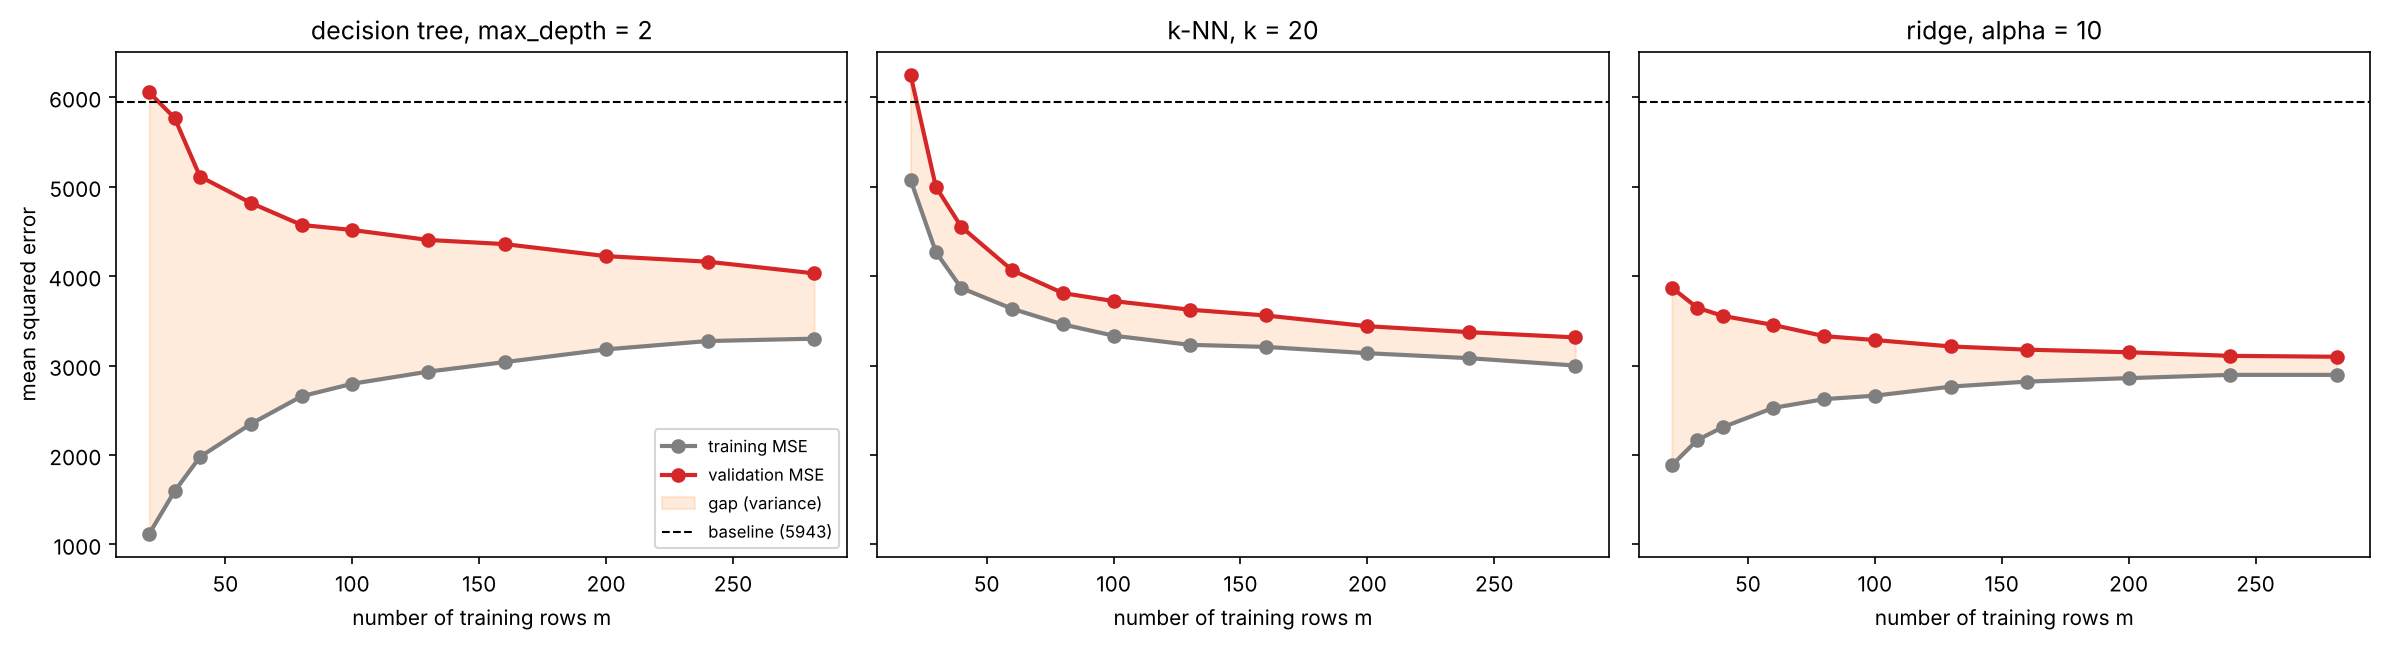

,train MSE @ m=282,val MSE @ m=282,gap @ m=282,val MSE drop from m=160 to m=282
"decision tree, max_depth = 2",3300.6,4030.9,730.2,327.2
"k-NN, k = 20",2999.9,3314.8,314.9,245.0
"ridge, alpha = 10",2895.7,3098.5,202.8,79.4


In [ ]:
best_of_family_models = {}                           # maps each family to (setting text, untrained model)
for i in cv_table_r.groupby("model")["CV MSE"].idxmin():   # position of the best candidate of each family
    family, hp, value, model = candidates_r[i]       # unpack the candidate
    best_of_family_models[family] = (f"{hp} = {value:g}", model)  # keep its setting and model

sizes_r = np.array([20, 30, 40, 60, 80, 100, 130, 160, 200, 240, 282])   # 282 = smallest training part of folds_db
N_LC_REPEATS = 10                                    # repeated 5-fold, as in 6b

lc_summary_r = {}                                    # maps each model to its numbers at m = 282
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)  # three panels, one per family
for ax, (family, (setting, model)) in zip(axes, best_of_family_models.items()):
    tr_all, va_all = [], []                          # the (11, 5) arrays of every repeat
    for r in range(N_LC_REPEATS):
        folds_r = kfold_indices(len(yr_dev), 5, seed=100 + r)           # a new set of plain folds per repeat
        t, v = learning_curve_errors(model, Xr_dev, yr_dev, folds_r, sizes_r, seed=r, error_fn=mse)
        tr_all.append(t)                             # training errors of this repeat
        va_all.append(v)                             # validation errors of this repeat
    tr_mean = np.concatenate(tr_all, axis=1).mean(axis=1)               # average over all 50 fits per size
    va_mean = np.concatenate(va_all, axis=1).mean(axis=1)  # the same for validation
    name = f"{family}, {setting}"                    # panel title and table row name
    lc_summary_r[name] = {"train MSE @ m=282": tr_mean[-1], "val MSE @ m=282": va_mean[-1],
                          "gap @ m=282": va_mean[-1] - tr_mean[-1],
                          "val MSE drop from m=160 to m=282": va_mean[sizes_r == 160][0] - va_mean[-1]}

    ax.plot(sizes_r, tr_mean, "o-", color="tab:grey", lw=2, label="training MSE")  # training curve
    ax.plot(sizes_r, va_mean, "o-", color="tab:red", lw=2, label="validation MSE")  # validation curve
    ax.fill_between(sizes_r, tr_mean, va_mean, color="tab:orange", alpha=0.15, label="gap (variance)")  # gap
    ax.axhline(baseline, color="black", ls="dashed", lw=1, label=f"baseline ({baseline:.0f})")  # baseline
    ax.set_title(name)                               # panel title
    ax.set_xlabel("number of training rows m")       # x-axis label
axes[0].set_ylabel("mean squared error")             # y-axis label, left panel only
axes[0].legend(fontsize=8)                           # legend on the left panel
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

pd.DataFrame(lc_summary_r).T.round(1)                # one row per model

**Line by line**

- The first loop turns the "best of family" positions of step 2 into a dictionary from the family name to its
  setting (as text, for the titles) and its untrained model. `groupby` lists the families in alphabetical order:
  decision tree, k-NN, ridge.
- `sizes_r` : the training-set sizes. The largest is 282, the size of the smallest training part of a 5-fold split of
  353 rows. The smallest is 20, because a k-NN model with $k = 20$ cannot be fitted on fewer than 20 rows (it would
  have fewer rows than neighbours to average).
- `N_LC_REPEATS = 10` and `kfold_indices(len(yr_dev), 5, seed=100 + r)` : 10 different 5-fold splits, so every point
  of a curve is an average over 50 fitted models, as in 6b. Plain folds, because regression has no classes.
- `learning_curve_errors(..., error_fn=mse)` : the function of 6a, with the MSE as the error.
- `np.concatenate(tr_all, axis=1).mean(axis=1)` : glues the ten `(11, 5)` arrays into one `(11, 50)` array and
  averages each row, giving one training MSE per size (same recipe as 6b).
- `va_mean[sizes_r == 160][0]` : the validation MSE at $m = 160$. `sizes_r == 160` is a boolean mask that is `True`
  at one position; indexing with it gives a one-element array, and `[0]` takes the number out.
- The plotting lines are those of 6b, plus a dashed horizontal line at the baseline. `ls="dashed"` draws a dashed
  line.
- `pd.DataFrame(lc_summary_r).T` : one row per model with the numbers at the largest size.

**Reading the output.**

- **Ridge, $\alpha = 10$:** the two curves have almost met. At $m = 282$ the gap is 203, and between 160 and 282
  training rows the validation MSE falls by only 79. The model has learned almost all it can from these ten features;
  what is left is bias of a linear model and noise in the target.
- **k-NN, $k = 20$:** the validation MSE is still falling at the right edge (by 245 between 160 and 282 rows), with a
  gap of 315. Notice the unusual training curve: it **falls** as $m$ grows. With $m = 20$ and $k = 20$ every
  prediction is the average of all 20 training rows, a constant, so the training MSE is large. As $m$ grows, the 20
  neighbours come from a smaller and smaller region, so the model becomes more flexible. For k-NN a fixed $k$ means a
  model that grows more complex with more data (the "$n/k$ parameters" of 5a).
- **Tree, depth 2:** the largest gap (730) and the steepest fall at the right edge (327 between 160 and 282 rows).
  The four leaves and their split points are estimated from few rows and change a lot from one training set to the
  next.

**Answer.** More data would help the **regression tree** most, then **k-NN**: both still have a large gap and a
validation curve that is clearly falling at the right edge. Ridge would gain little, because its curves have nearly
converged. But "helps most" is not the same as "would become the best model". For the depth-2 tree the training MSE
rises towards the level both curves are heading for, and it is already 3301, above ridge's 3099; even unlimited data
would leave this tree behind ridge. To use more data well, the tree would also need to grow deeper.

## 3.4 The final model and its single test evaluation

In [ ]:
from sklearn.metrics import r2_score                 # the library's R^2, used only to check ours

final_model_r = clone(model_r).fit(Xr_dev, yr_dev)   # step 5: refit the winner on all 353 development patients

# step 6: the ONE AND ONLY use of the regression test set
yr_test_pred = final_model_r.predict(Xr_test)        # 89 predictions, one per test patient

test_mse_r = mse(yr_test, yr_test_pred)              # mean squared error on the 89 test patients
r2_test = 1 - test_mse_r / yr_test.var()             # coefficient of determination
squared_errors = (yr_test - yr_test_pred) ** 2       # one squared error per test patient
se_mse = squared_errors.std() / np.sqrt(len(yr_test))   # standard error of their mean
cv_mse_r = cv_table_r.loc[best_r_idx, "CV MSE"]      # the winner's CV error, used for CHOOSING

print(f"final model : {family_r} with {hp_r} = {value_r:g}, refitted on {len(yr_dev)} development patients")
print(f"CV MSE on the development set (used for CHOOSING) : {cv_mse_r:.1f}")
print(f"TEST MSE, unbiased (used for REPORTING)           : {test_mse_r:.1f}"
      f"   (standard error {se_mse:.1f}, approximate 95% interval"
      f" [{test_mse_r - 1.96 * se_mse:.0f}, {test_mse_r + 1.96 * se_mse:.0f}])")
print(f"variance of the test targets                      : {yr_test.var():.1f}")
print(f"R^2 on the test set                               : {r2_test:.4f}")
print(f"R^2 identical to sklearn's r2_score               : {np.isclose(r2_test, r2_score(yr_test, yr_test_pred))}")
print(f"for comparison, 1 - CV MSE / Var(yr_dev)           : {1 - cv_mse_r / yr_dev.var():.4f}")

final model : ridge with alpha = 10, refitted on 353 development patients
CV MSE on the development set (used for CHOOSING) : 3075.2
TEST MSE, unbiased (used for REPORTING)           : 2741.5   (standard error 423.2, approximate 95% interval [1912, 3571])
variance of the test targets                      : 5936.4
R^2 on the test set                               : 0.5382
R^2 identical to sklearn's r2_score               : True
for comparison, 1 - CV MSE / Var(yr_dev)           : 0.4811


**Line by line**

- `from sklearn.metrics import r2_score` : scikit-learn's $R^2$, imported only to check our one-line formula.
- `clone(model_r).fit(Xr_dev, yr_dev)` : step 5 of the protocol. A fresh copy of the winning pipeline (scaler plus
  ridge with $\alpha = 10$) is trained on **all** development patients; the validation folds have done their job and
  are now simply more training data.
- `final_model_r.predict(Xr_test)` : step 6, the only line in the whole notebook that touches `Xr_test`.
- `yr_test.var()` : the variance of the test targets, i.e. the MSE of the best possible **constant** prediction for
  these 89 patients. Dividing the model's MSE by it and subtracting from 1 gives $R^2$.
- `squared_errors.std() / np.sqrt(len(yr_test))` : the test MSE is an average of 89 squared errors, so its standard
  error is their standard deviation divided by $\sqrt{89}$ (the same reasoning as the standard error of the test
  error rate in 7e).
- `np.isclose(r2_test, r2_score(...))` : `r2_score` computes $1 - \sum (y - \hat y)^2 / \sum (y - \bar y)^2$; dividing
  the top and the bottom by $n$ turns it into exactly our formula.
- The last line computes the same kind of number from the CV MSE and the development targets, for comparison.

**Reading the output.**

- The final model is ridge regression with $\alpha = 10$. Its **test MSE is 2741.5** and its **test $R^2$ is 0.538**:
  on new patients it explains a little over half of the variation in disease progression. The other half is not
  predictable from these ten measurements, at least not by any of our candidate models.
- The test MSE is **lower** than the CV MSE (3075.2). That is the opposite of the direction 7f warns about, and it is
  not a contradiction: the standard error of the test MSE is about 423, so the 95% interval runs from about 1912 to
  3571 and contains the CV value comfortably. With 89 patients, and squared errors in which a few badly predicted
  patients weigh heavily, the test MSE is unbiased but **imprecise**. This test set simply happened to contain
  patients that are a little easier to predict.
- $R^2$ agrees with scikit-learn's `r2_score`.
- This is the number that goes in the report: test MSE 2742 (test $R^2 = 0.54$). We must not now go back, look for a
  model that does even better on these 89 patients, and report that.

## 3.5 Stratified folds for a regression problem

In [ ]:
quintile_edges = np.quantile(yr_dev, [0.2, 0.4, 0.6, 0.8])   # 4 cut points: 20%, 40%, 60%, 80% of the targets
groups = np.digitize(yr_dev, quintile_edges)                 # group number 0..4 for every patient
print("cut points         :", quintile_edges)
print("patients per group :", np.bincount(groups))

plain_f = kfold_indices(len(yr_dev), 5, seed=0)      # plain folds, for comparison
strat_f = stratified_kfold_indices(groups, 5, seed=0)        # stratify on the GROUP numbers
print("mean target per plain fold      :", np.round([yr_dev[va].mean() for _, va in plain_f], 1))
print("mean target per stratified fold :", np.round([yr_dev[va].mean() for _, va in strat_f], 1))

N_SHUFFLES = 100                                     # number of shuffles
rows = []                                            # one dictionary per row of the table
for family, (setting, model) in best_of_family_models.items():
    plain_est = np.empty(N_SHUFFLES)                 # CV MSE of every plain shuffle
    strat_est = np.empty(N_SHUFFLES)                 # CV MSE of every stratified shuffle
    for s in range(N_SHUFFLES):
        _, v = cross_val_errors(model, Xr_dev, yr_dev, kfold_indices(len(yr_dev), 5, seed=s), error_fn=mse)
        plain_est[s] = v.mean()                      # CV MSE of this plain split
        _, v = cross_val_errors(model, Xr_dev, yr_dev, stratified_kfold_indices(groups, 5, seed=s), error_fn=mse)
        strat_est[s] = v.mean()                      # CV MSE of this stratified split
    rows.append({"model": f"{family}, {setting}",    # one row per model
                 "plain: mean CV MSE": plain_est.mean(), "plain: std": plain_est.std(),
                 "stratified: mean CV MSE": strat_est.mean(), "stratified: std": strat_est.std(),
                 "std ratio (stratified / plain)": strat_est.std() / plain_est.std()})
pd.DataFrame(rows).set_index("model").round(2)       # display the table

cut points         : [ 77.4 117.6 164.  231.2]
patients per group : [71 70 70 71 71]
mean target per plain fold      : [155.1 146.5 149.6 161.6 150.9]
mean target per stratified fold : [155.1 152.3 150.9 154.1 151.1]


,plain: mean CV MSE,plain: std,stratified: mean CV MSE,stratified: std,std ratio (stratified / plain)
model,,,,,
"decision tree, max_depth = 2",3948.67,148.40,3955.32,150.78,1.02
"k-NN, k = 20",3328.95,56.66,3307.69,52.69,0.93
"ridge, alpha = 10",3100.66,42.31,3085.15,43.85,1.04


**Line by line**

- `np.quantile(yr_dev, [0.2, 0.4, 0.6, 0.8])` : the values below which 20%, 40%, 60% and 80% of the development
  targets lie. These four cut points divide the patients into five equally large groups, the **quintiles**.
- `np.digitize(yr_dev, quintile_edges)` : for every patient, the number of cut points that its target is greater than
  or equal to. A patient below the first cut point gets group 0, one above the last gets group 4.
- `np.bincount(groups)` : the size of each group, about 70 patients each.
- `stratified_kfold_indices(groups, 5, seed=0)` : the function never knew it was meant for classes. It sees five
  "labels" and gives every fold the same share of each, so every fold receives about the same number of low,
  medium and high progression values.
- `yr_dev[va].mean()` for every fold : the average target of each validation fold, to see the effect directly.
- The loop repeats plain and stratified 5-fold CV for 100 shuffles, for the best model of each family, and records
  the mean and the standard deviation of the 100 CV estimates.
- `"std ratio (stratified / plain)"` : below 1 means stratification made the estimate less noisy.

**Reading the output.**

- Stratification does what it promises for the folds themselves: the mean target per fold ranges from 146.5 to 161.6
  with plain folds, but only from 150.9 to 155.1 with stratified folds.
- It does **not** make the CV estimate less noisy here. The ratios of the standard deviations are 1.02 for the tree,
  0.93 for k-NN and 1.04 for ridge: one a little below 1, two a little above, all within the uncertainty of a
  standard deviation estimated from 100 repeats (about 7%). The mean CV MSE values also barely move.

**Answer.** Yes, a regression problem can be stratified: cut the target into bins and stratify on the bin numbers.
This is the usual way to do it, since scikit-learn's `StratifiedKFold` itself expects classes. It makes the folds
alike in their distribution of targets. On the Diabetes data it does not make the CV estimate measurably less noisy,
for the same reason as in Exercise 2, step 4: every patient is still predicted exactly once by a model trained on
80% of the data, and balancing the folds hardly changes those predictions. Stratifying on the target is more useful
for small datasets, or when the target has a few extreme values that could otherwise end up together in one fold.

# Exercise 4: Data leakage

**Task.**

1. Create a world with no signal and many features: 200 rows, 2000 features of pure noise, and labels that are fair
   coin flips. Every classifier has a true error of 0.5 here.
2. **The wrong way.** Using all 200 rows, keep the 20 features with the largest absolute correlation with the
   labels, then run stratified 5-fold CV of 5-NN (or logistic regression) on those 20 features. Report the CV error.
3. **The right way.** Do the feature selection inside the cross-validation loop, using the training rows of each
   fold only. Report the CV error.
4. Explain the difference. Which rule of the practical does the wrong way break? Why does putting `StandardScaler`
   inside the pipeline protect us from a milder version of the same mistake?
5. *(Optional)* On the breast-cancer data, standardise `X_dev` once using all its rows, then run k-NN
   cross-validation without a scaler in the pipeline. Is this leak noticeable? Why is scaling a much milder leak than
   feature selection?

**Concept.** **Leakage** happens when information from the rows used for evaluation reaches the model during
training. The validation error is then no longer an error on unseen data, and it is always too optimistic.

The important point is what counts as "training". It is not only the call to `fit`. **Every step that looks at the
data and makes a decision is part of training**: computing the mean and standard deviation for scaling, choosing
which features to keep, filling in missing values, choosing a threshold. If such a step sees the validation rows,
the validation rows have helped to build the model that is evaluated on them.

**Why noise features can look useful.** With 200 rows, the correlation of a pure-noise feature with the labels is
not exactly 0; it is a random number with a standard deviation of about $1/\sqrt{200} \approx 0.07$. Among 2000 such
features some will, purely by chance, have correlations of 0.2 or more. Picking the 20 largest means picking the 20
luckiest, the winner's curse of 7f once more, now applied to features instead of models.

## 4.1 A world with no signal

In [ ]:
rng_ex4 = np.random.default_rng(4)                   # this exercise's own seeded generator
X_leak = rng_ex4.normal(size=(200, 2000))            # 200 rows, 2000 features of pure noise
y_leak = rng_ex4.integers(0, 2, size=200)            # labels: fair coin flips, unrelated to X_leak

print("X_leak:", X_leak.shape, "   y_leak class counts:", np.bincount(y_leak))

X_leak: (200, 2000)    y_leak class counts: [ 98 102]


**Line by line**

- `np.random.default_rng(4)` : a dedicated generator with seed 4, instead of the shared `rng` (see the introduction).
- `rng_ex4.normal(size=(200, 2000))` : a $200 \times 2000$ matrix of independent standard normal numbers. There are
  ten times more features than rows, which is common in, for example, gene-expression data.
- `rng_ex4.integers(0, 2, size=200)` : 200 independent draws of 0 or 1, each with probability 1/2. Nothing links them
  to `X_leak`, so the best possible error rate is 0.5.
- `np.bincount(y_leak)` : 98 zeros and 102 ones, close to half and half as expected.

## 4.2 The wrong way: select features on all rows, then cross-validate

In [ ]:
def correlations(X, y):
    '''Correlation of every column of X with y, as one matrix-vector product (the hint of the exercise).'''
    X_std = (X - X.mean(axis=0)) / X.std(axis=0)     # every column rescaled to mean 0, std 1
    y_std = (y - y.mean()) / y.std()                 # the labels rescaled to mean 0, std 1
    return X_std.T @ y_std / len(y)                  # (d,) vector: average product = correlation


def top_features(X, y, n_keep):
    '''Column numbers of the n_keep features with the largest absolute correlation with y, sorted.'''
    corr = correlations(X, y)                        # one correlation per column
    strongest = np.argsort(-np.abs(corr))[:n_keep]   # positions of the n_keep largest |corr|
    return np.sort(strongest)                        # sorted, so the columns keep their original order


corr_all = correlations(X_leak, y_leak)              # correlations computed from ALL 200 rows
print("check against np.corrcoef for column 0 :", np.isclose(corr_all[0], np.corrcoef(X_leak[:, 0], y_leak)[0, 1]))
print(f"median |correlation| of a noise feature : {np.median(np.abs(corr_all)):.3f}")
print(f"largest |correlation| of the 2000       : {np.abs(corr_all).max():.3f}")

top_all = top_features(X_leak, y_leak, 20)           # WRONG: chosen using the labels of all 200 rows
print(f"20th largest |correlation| (kept)       : {np.sort(np.abs(corr_all))[-20]:.3f}\n")

folds_leak = stratified_kfold_indices(y_leak, 5, seed=0)                  # stratified 5-fold, as asked
logreg_pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))  # scaler + logistic
models_leak = [("5-NN", make_knn(5)), ("logistic regression", logreg_pipe)]  # the two models

wrong_way = {}                                       # maps each model name to its CV error
for name, model in models_leak:
    _, v = cross_val_errors(model, X_leak[:, top_all], y_leak, folds_leak)   # CV on the 20 pre-chosen columns
    wrong_way[name] = v.mean()                       # keep the CV error
    print(f"WRONG way, {name:<20}: CV error = {v.mean():.3f}    fold errors {v}")

check against np.corrcoef for column 0 : True
median |correlation| of a noise feature : 0.049
largest |correlation| of the 2000       : 0.223
20th largest |correlation| (kept)       : 0.185

WRONG way, 5-NN                : CV error = 0.285    fold errors [0.225 0.275 0.35  0.25  0.325]
WRONG way, logistic regression : CV error = 0.245    fold errors [0.25  0.225 0.325 0.2   0.225]


**Line by line**

- `correlations(X, y)` : the formula of the hint.
  - `(X - X.mean(axis=0)) / X.std(axis=0)` : subtract every column's mean and divide by its standard deviation, so
    every column has mean 0 and standard deviation 1. `axis=0` computes one mean and one std per column.
  - `(y - y.mean()) / y.std()` : the same for the label vector.
  - `X_std.T @ y_std / len(y)` : the matrix-vector product of Practical 1. Entry $j$ is
    $\frac{1}{n}\sum_i x_{ij}^{\text{std}} \, y_i^{\text{std}}$, the average product of two standardised variables,
    which is exactly their correlation. One product computes all 2000 correlations at once.
- `top_features(X, y, n_keep)` :
  - `np.abs(corr)` : the strength of a correlation, ignoring its sign (a strong negative correlation is as useful as
    a strong positive one).
  - `np.argsort(-np.abs(corr))` : `argsort` returns the positions that would sort an array in **increasing** order;
    sorting the **negated** values therefore gives the positions in decreasing order of strength. `[:n_keep]` keeps the
    first 20.
  - `np.sort(strongest)` : puts the 20 column numbers in increasing order. The set of columns is the same; sorting
    only makes it easy to compare with scikit-learn in 4.3, which also keeps columns in their original order.
- `np.corrcoef(a, b)[0, 1]` : NumPy's own correlation of two vectors, used once to check our formula.
- `np.median(np.abs(corr_all))` and `.max()` : a typical and the largest correlation among the 2000 noise features.
- `top_all = top_features(X_leak, y_leak, 20)` : **this is the leak**. The labels of all 200 rows, including every
  row that will later sit in a validation fold, decide which 20 columns are kept.
- `stratified_kfold_indices(y_leak, 5, seed=0)` : our stratified folds of Part 4.
- `X_leak[:, top_all]` : all rows, only the 20 chosen columns. Cross-validation then runs on this reduced matrix as
  if those 20 columns had been given to us in advance.
- `f"{name:<20}"` : left-aligns the model name in a field 20 characters wide, so the lines line up.

**Reading the output.**

- The correlation formula agrees with `np.corrcoef`.
- A typical noise feature has a correlation of about 0.05 with the labels, but the largest of the 2000 reaches 0.223,
  and the 20 that are kept all have at least 0.185. These are not real relationships; they are the luckiest 1% of
  2000 random numbers.
- On those 20 features, cross-validation reports an error of **0.285 for 5-NN and 0.245 for logistic regression**.
  Taken at face value, that is a classifier that is right 72% to 76% of the time on data in which there is nothing
  to learn.

## 4.3 The right way: select features inside every fold

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif   # library feature selection, used only to check


def cross_val_errors_with_selection(model, X, y, folds, n_keep, error_fn=error_rate):
    '''Cross-validation in which the feature selection is part of training, so it is redone inside every fold.

    returns : (val_errors, chosen), one validation error and one array of chosen column numbers per fold
    '''
    val_errors = np.empty(len(folds))                # one validation error per fold
    chosen = []                                      # the columns chosen in each fold
    for j, (tr, va) in enumerate(folds):
        feats = top_features(X[tr], y[tr], n_keep)   # selection uses the TRAINING rows of this fold only
        fitted = clone(model).fit(X[tr][:, feats], y[tr])                   # fit on those rows and columns
        val_errors[j] = error_fn(y[va], fitted.predict(X[va][:, feats]))   # score the untouched fold
        chosen.append(feats)                         # remember which columns this fold kept
    return val_errors, chosen


right_way = {}                                       # maps each model name to its CV error
for name, model in models_leak:
    v, chosen = cross_val_errors_with_selection(model, X_leak, y_leak, folds_leak, n_keep=20)
    right_way[name] = v.mean()                       # keep the CV error
    print(f"RIGHT way, {name:<20}: CV error = {v.mean():.3f}    fold errors {v}")

    # the library check: selection as the first step of a pipeline, so cross_validate refits it in every fold
    lib = cross_validate(make_pipeline(SelectKBest(f_classif, k=20), clone(model)),
                         X_leak, y_leak, cv=folds_leak, scoring="accuracy")
    print(f"           identical to SelectKBest inside the pipeline: {np.allclose(v, 1 - lib['test_score'])}")

print("\ncolumns shared by each fold's top 20 and the all-rows top 20:",
      [len(np.intersect1d(f, top_all)) for f in chosen])

RIGHT way, 5-NN                : CV error = 0.565    fold errors [0.5   0.525 0.625 0.6   0.575]
           identical to SelectKBest inside the pipeline: True


RIGHT way, logistic regression : CV error = 0.520    fold errors [0.5   0.425 0.65  0.575 0.45 ]
           identical to SelectKBest inside the pipeline: True

columns shared by each fold's top 20 and the all-rows top 20: [10, 10, 10, 7, 7]


**Line by line**

- `from sklearn.feature_selection import SelectKBest, f_classif` : scikit-learn's tool for keeping the $k$ best
  features according to a score, and the score it uses for classification.
- `cross_val_errors_with_selection(...)` : the loop of `cross_val_errors`, with one line added at the top of each
  fold.
  - `top_features(X[tr], y[tr], n_keep)` : the correlations are computed from the **training rows of this fold
    only**. The validation rows of the fold play no part in the choice.
  - `X[tr][:, feats]` : first the training rows, then the chosen columns.
  - `fitted.predict(X[va][:, feats])` : the validation rows, restricted to the **same** columns, which were chosen
    without them.
  - `chosen.append(feats)` : keeps each fold's selection so we can compare the selections afterwards.
  - The training error is not computed, because this exercise does not need it.
- `make_pipeline(SelectKBest(f_classif, k=20), clone(model))` : the library way to do the same thing. Because the
  selection is the **first step of the pipeline**, `cross_validate` refits it, together with the model, on the
  training rows of every fold; exactly the principle of the `StandardScaler` in section 0c.
- Why `f_classif` picks the same 20 columns as our correlations: for two classes, `f_classif` computes the ANOVA F
  statistic of every feature, which equals $F = (n - 2)\, r^2 / (1 - r^2)$, where $r$ is the correlation of the
  feature with the 0/1 labels. $F$ grows when $|r|$ grows, so ranking by $F$ and ranking by $|r|$ give the same 20
  features.
- `np.allclose(v, 1 - lib['test_score'])` : the library reports accuracy, so `1 - accuracy` gives the error rate.
- `np.intersect1d(f, top_all)` : the columns that a fold's selection shares with the leaky all-rows selection.

**Reading the output.**

- With the selection done inside the folds, the CV error is **0.565 for 5-NN and 0.520 for logistic regression**,
  close to the true value of 0.5. Both are slightly above 0.5, which is noise: with 200 rows the standard error of
  an error rate near 0.5 is about $\sqrt{0.25/200} \approx 0.035$.
- Our fold errors are identical to those of `SelectKBest` inside a pipeline, for both models.
- Each fold's top 20 shares only 7 to 10 columns with the top 20 chosen from all rows. Remove a fifth of the rows
  and half of the "best" features are replaced by others. That is what you would expect from correlations that are
  pure chance; a real relationship would reappear in every fold.

**Is the gap luck?** One noise world could be unusual, so we repeat both procedures in 20 new noise worlds.

wrong way over 20 worlds: mean 0.298, from 0.220 to 0.365
right way over 20 worlds: mean 0.485, from 0.380 to 0.555


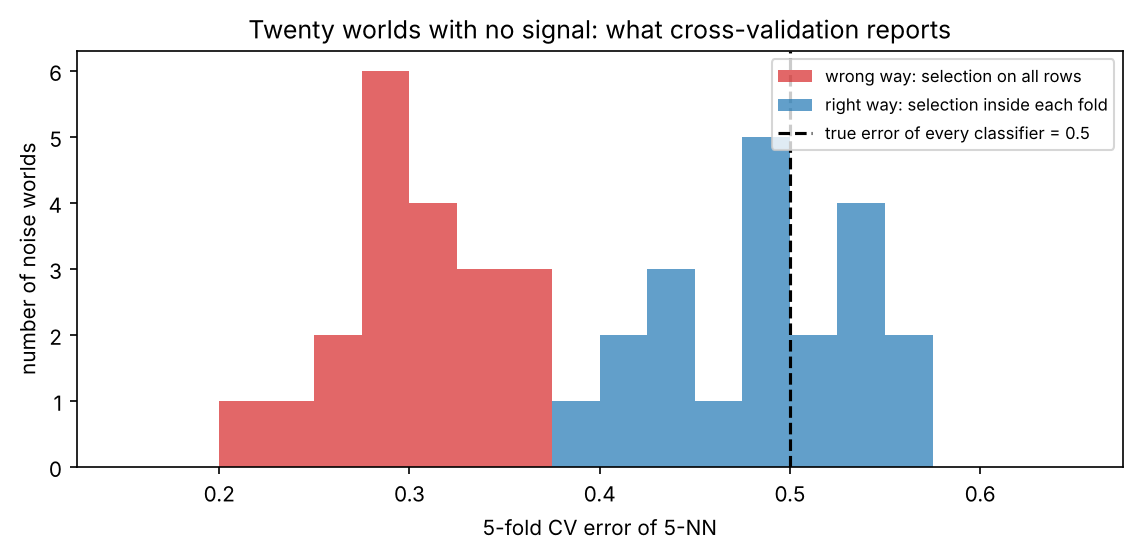

In [ ]:
N_WORLDS = 20                               # number of independent noise worlds
wrong_w = np.empty(N_WORLDS)                         # CV error of the wrong way, one per world
right_w = np.empty(N_WORLDS)                         # CV error of the right way, one per world
for w in range(N_WORLDS):
    rng_w = np.random.default_rng(1000 + w)          # a separate seed for every world
    X_w = rng_w.normal(size=(200, 2000))             # a new noise matrix ...
    y_w = rng_w.integers(0, 2, size=200)             # ... and new coin-flip labels
    folds_w = stratified_kfold_indices(y_w, 5, seed=0)  # stratified folds of this world
    _, v = cross_val_errors(make_knn(5), X_w[:, top_features(X_w, y_w, 20)], y_w, folds_w)   # wrong way
    wrong_w[w] = v.mean()                            # CV error, wrong way
    v, _ = cross_val_errors_with_selection(make_knn(5), X_w, y_w, folds_w, n_keep=20)        # right way
    right_w[w] = v.mean()                            # CV error, right way

print(f"wrong way over {N_WORLDS} worlds: mean {wrong_w.mean():.3f}, from {wrong_w.min():.3f} to {wrong_w.max():.3f}")
print(f"right way over {N_WORLDS} worlds: mean {right_w.mean():.3f}, from {right_w.min():.3f} to {right_w.max():.3f}")

fig, ax = plt.subplots(figsize=(9, 3.6))             # one panel
bins = np.arange(0.15, 0.66, 0.025)                  # bar edges every 0.025
ax.hist(wrong_w, bins=bins, color="tab:red", alpha=0.7, label="wrong way: selection on all rows")  # red
ax.hist(right_w, bins=bins, color="tab:blue", alpha=0.7, label="right way: selection inside each fold")
ax.axvline(0.5, color="black", ls="dashed", lw=1.5, label="true error of every classifier = 0.5")  # truth
ax.set_xlabel("5-fold CV error of 5-NN")             # x-axis label
ax.set_ylabel("number of noise worlds")              # y-axis label
ax.set_title("Twenty worlds with no signal: what cross-validation reports")  # title
ax.legend(fontsize=8, loc="upper right")             # legend in the empty corner
plt.show()                                           # draw the figure

**Line by line**

- `np.random.default_rng(1000 + w)` : every world gets its own seed, so the 20 worlds are independent of each other
  and of the world of 4.1.
- Inside the loop the two procedures of 4.2 and 4.3 are run on the same world and the same folds, so the only
  difference between them is **where** the feature selection happens.
- `ax.hist(...)` twice with `alpha=0.7` : two semi-transparent histograms on the same axes.
- `ls="dashed"` : a dashed vertical line at the true error.

**Reading the output.** In every one of the 20 worlds the wrong way reports an error far below 0.5 (on average 0.30,
never above 0.37), while the right way scatters around 0.5 (on average 0.48, never below 0.38). The two histograms do
not overlap at all: the worst result of the wrong way is still better than the best result of the right way. The
optimism of the wrong way is systematic, not bad luck.

## 4.4 Explaining the difference

**Answer.**

- **The two numbers.** The wrong way reports about 0.29 (5-NN) and 0.25 (logistic regression); the right way about
  0.57 and 0.52, consistent with the truth, 0.5. The wrong way chose the 20 features that correlate best with the
  labels of **all** 200 rows. Every validation fold is part of those 200 rows, so the chosen features are, by
  construction, ones that happen to line up with the validation labels too. When cross-validation then "tests" on a
  validation fold, it tests on rows whose labels helped to pick the features, and a k-NN or logistic model built on
  those features naturally does better than chance on them. On genuinely new rows the chance correlations vanish and
  the error is 0.5. The right way repeats the selection inside every fold, so the validation rows never influence
  the choice, and the estimate is honest.
- **The rule that is broken.** The validation rows must play no part in training the model that is scored on them
  (section 1a; rule 3 of the protocol in 7a says the same for the test set). Feature selection that uses the labels
  is part of training. It is also the habit stated at the start of the exercises: *which rows was this error computed
  on, and were those rows used to choose anything?* In the wrong way the validation rows were used to choose the
  features. Note that the mistake happens **before** any cross-validation code runs, which is what makes it so easy
  to miss: the loop itself is perfectly correct.
- **Why the scaler inside the pipeline protects us.** Scaling also looks at the data: it computes a mean and a
  standard deviation for every column. If we scaled `X_dev` once, before cross-validation, the validation rows of
  every fold would have contributed to the scaling of their own evaluation; a leak of the same kind, only milder.
  Putting `StandardScaler` inside the pipeline (section 0c) means that `cross_val_errors` refits it in every fold,
  on the training rows only. The general rule: **every step that learns something from the data belongs inside the
  pipeline**, so that cross-validation repeats it in every fold. 4.3 did exactly that for feature selection with
  `SelectKBest`.

## 4.5 (Optional) The milder leak: scaling once with all development rows

In [ ]:
X_dev_scaled_once = StandardScaler().fit_transform(X_dev)   # LEAKY: means and stds from all 454 development rows

rows = []                                            # one dictionary per row of the table
for k in k_values:
    _, v_ok = cross_val_errors(make_knn(k), X_dev, y_dev, folds_bc)              # correct: scaler inside
    _, v_leak = cross_val_errors(KNeighborsClassifier(n_neighbors=k),            # leaky: no scaler in the model,
                                 X_dev_scaled_once, y_dev, folds_bc)             # data scaled beforehand
    rows.append({"k": k, "correct (scaler inside)": v_ok.mean(), "leaky (scaled once)": v_leak.mean()})
leak_table = pd.DataFrame(rows).set_index("k")       # table indexed by k
leak_table["correct minus leaky"] = leak_table["correct (scaler inside)"] - leak_table["leaky (scaled once)"]

diff = leak_table["correct minus leaky"].round(12)   # differences without floating-point dust
print(f"largest difference in CV error             : {diff.abs().max():.4f}")
print(f"values of k where the leaky version is lower: {int((diff > 0).sum())},"
      f"  equal: {int((diff == 0).sum())},  higher: {int((diff < 0).sum())}  (out of {len(k_values)})")

# how much do the scaling statistics of a training fold differ from those of all development rows?
tr0, _ = folds_bc[0]                                 # the training rows of the first fold
mean_shift = np.abs(X_dev[tr0].mean(axis=0) - X_dev.mean(axis=0)) / X_dev.std(axis=0)
std_ratio = X_dev[tr0].std(axis=0) / X_dev.std(axis=0)  # ratio of the stds, per column
print(f"fold 1: column means differ by at most {mean_shift.max():.3f} standard deviations,"
      f" column stds by at most {np.abs(std_ratio - 1).max():.1%}")

leak_table.T                                         # display, k across the page

largest difference in CV error             : 0.0066
values of k where the leaky version is lower: 8,  equal: 9,  higher: 1  (out of 18)
fold 1: column means differ by at most 0.061 standard deviations, column stds by at most 8.3%


k,1,2,3,4,5,7,9,11,15,21,31,41,61,81,121,161,221,301
correct (scaler inside),0.0506,0.0462,0.0374,0.0396,0.0330,0.0397,0.0375,0.0419,0.0419,0.0463,0.0463,0.0507,0.0551,0.0705,0.0859,1.1668e-01,0.1806,0.3722
leaky (scaled once),0.0484,0.0462,0.0374,0.0396,0.0352,0.0397,0.0308,0.0375,0.0419,0.0397,0.0463,0.0485,0.0551,0.0683,0.0836,1.1665e-01,0.1806,0.3722
correct minus leaky,0.0022,0.0000,0.0000,0.0000,-0.0022,0.0000,0.0066,0.0044,0.0000,0.0066,0.0000,0.0022,0.0000,0.0022,0.0022,2.4420e-05,0.0000,0.0000


**Line by line**

- `StandardScaler().fit_transform(X_dev)` : `fit` computes the mean and standard deviation of every column from all
  454 development rows, and `transform` rescales the columns with them; `fit_transform` does both. This is the leak:
  the rows of every future validation fold have helped to compute these numbers.
- `cross_val_errors(make_knn(k), X_dev, ...)` : the correct version, as everywhere in the practical: the scaler is
  part of the model and is refitted on the training rows of each fold.
- `cross_val_errors(KNeighborsClassifier(n_neighbors=k), X_dev_scaled_once, ...)` : the leaky version: a bare k-NN
  model, without a scaler, on data that was scaled beforehand.
- Both use `folds_bc`, the stratified folds of 5a, so the only difference is where the scaling statistics came from.
- `leak_table["correct minus leaky"]` : positive values mean the leaky version **looks better**.
- `.round(12)` : removes floating-point dust before counting the positive, zero and negative differences.
- `(diff > 0).sum()` : the number of `True` values, i.e. the number of $k$ for which the leaky estimate is lower.
- `mean_shift`, `std_ratio` : compare the statistics that the correct pipeline uses in fold 1 (computed from that
  fold's 363 training rows) with those of the leaky version (all 454 rows). The mean difference is expressed in units
  of the column's standard deviation; `:.1%` prints a fraction as a percentage.

**Reading the output.**

- For 9 of the 18 values of $k$ the two estimates are identical, and the largest difference is 0.0066, about three
  mistakes out of 454 (at $k = 9$ and $k = 21$). The leaky version looks slightly better for 8 values of $k$ (for
  $k = 161$ by only 0.00002, the same number of mistakes spread differently over the folds) and worse for one
  ($k = 5$). So the leak has a small optimistic tendency, but every difference is far smaller than the fold-to-fold
  noise of the estimates (the "val std" column of 5a is around 0.01 to 0.02). On this dataset the leak is hardly
  noticeable.
- The reason is visible in the last printed line: computed from 363 or from 454 rows, the column means differ by at
  most 0.06 standard deviations and the standard deviations by at most 8%. Rescaling with almost the same numbers
  gives almost the same distances, so k-NN finds almost the same neighbours.

**Answer.** Scaling is a much milder leak than feature selection for three reasons. (1) It uses only the **features**
of the validation rows, never their **labels**, so it cannot pick up a chance relationship between features and
labels, which is what made the wrong way of 4.2 so optimistic. (2) It estimates only two numbers per column, and
with hundreds of rows those numbers hardly change when a fifth of the rows is added. (3) It makes no **choice**: the
same rescaling is applied whatever the data look like, whereas feature selection picks the 20 winners out of 2000.
The habit should still be kept: with small datasets, extreme outliers, or steps that use the labels (feature
selection, target encoding, choosing a threshold, oversampling a rare class), the same pattern produces large
leaks. Fitting every such step inside the pipeline makes the question disappear.

# Exercise 5: The one-standard-error rule and nested cross-validation

**Task.**

1. **The one-standard-error rule.** For the best $k$ of 5a, compute the standard error of its CV error as
   `val std / sqrt(K)`. Choose the **largest** $k$ (the simplest model) whose CV error is at most
   `best CV error + standard error`. Apply the same rule to the tree depths of `tree_curve`. Why might a simpler model
   be preferable when the errors are statistically indistinguishable?
2. **Nested cross-validation.** Estimate the error of the whole procedure "select by CV, then refit" without touching
   the test set: an outer stratified 5-fold loop (`seed=1`); inside each outer fold, the full selection of 7c on the
   outer training rows only (inner folds `stratified_kfold_indices(y_outer_train, 5, seed=0)`), a refit of the inner
   winner, and its error on the outer validation fold. Report the winner of each outer fold and the average outer
   error.
3. Check the nested CV against `cross_validate(GridSearchCV(...), ...)`. Why do the inner folds match?
4. Put three numbers side by side: the best CV error of 7c, the nested CV estimate and the test error of 7e. Which of
   the first two is the honest estimate of the test error? How many model fits did nested CV need?

**Concept: the one-standard-error rule.** A CV error is an average of $K$ fold errors, so it has a standard error,
roughly $\text{SE} = \text{std over folds} / \sqrt{K}$. Values of the hyper-parameter whose CV errors lie within one
SE of the minimum cannot be told apart with the data we have. Among them, the rule picks the **simplest** model. For
k-NN "simplest" means the largest $k$, for a tree the smallest depth, for ridge and logistic regression the
strongest penalty (largest $\alpha$, smallest $C$).

**Concept: nested cross-validation.** In 7c, the same five folds were used to **choose** the winner and to **score**
it. 7f showed that a score obtained this way is optimistic. Nested CV separates the two jobs with two loops:

- the **inner** loop chooses: it is the complete model selection of 7c, run on the outer training rows only;
- the **outer** loop scores: the chosen model is evaluated on an outer fold that played no part in choosing it.

The outer fold therefore plays exactly the role of the test set in 7e, five times over. What nested CV estimates is
the error of the **procedure** "choose by CV, then refit", which is the procedure that produced our final model.

## 5.1 The one-standard-error rule

In [ ]:
K = 5                                                # number of folds behind knn_curve, tree_curve and cv_table


def one_se_choice(errors, stds, simplest_first, n_folds=K):
    '''One-standard-error rule.

    errors, stds   : pandas Series of CV errors and of std over folds, indexed by hyper-parameter value
    simplest_first : the hyper-parameter values, ordered from the simplest model to the most complex one
    returns        : dictionary with the best value, its standard error, the threshold and the chosen value
    '''
    best = errors.idxmin()                           # the value with the smallest CV error
    se = stds[best] / np.sqrt(n_folds)               # standard error of that CV error
    threshold = errors[best] + se                    # "as good as the best", within one standard error
    within = [v for v in simplest_first if errors[v] <= threshold]   # all values under the threshold
    return {"best": best, "best CV error": errors[best], "SE": se, "threshold": threshold,
            "within one SE (simplest first)": within, "chosen by the rule": within[0]}


rule_rows = {}                                       # maps each family to the result of the rule
rule_rows["k-NN classifier (5a), k"] = one_se_choice(  # the k-NN curve of 5a
    knn_curve["val mean"], knn_curve["val std"], simplest_first=sorted(k_values, reverse=True))
rule_rows["regression tree (5c), max_depth"] = one_se_choice(  # the tree curve of 5c
    tree_curve["val MSE"], tree_curve["val std"], simplest_first=depths)

# the same rule on the other families of this practical
lr = cv_table[cv_table["model"] == "logistic regression"].copy()  # the 6 logistic rows of 7c
lr.index = [c for f, _, c, _ in candidates if f == "logistic regression"]          # index by the value of C
rule_rows["logistic regression (7c), C"] = one_se_choice(  # logistic regression of 7c
    lr["CV error"], lr["std over folds"], simplest_first=sorted(lr.index))

for family, name in [("k-NN", "k-NN regressor (Ex. 3), k"), ("ridge", "ridge (Ex. 3), alpha")]:
    part = cv_table_r[cv_table_r["model"] == family].copy()  # the rows of one family
    part.index = [v for f, _, v, _ in candidates_r if f == family]                 # index by the value
    rule_rows[name] = one_se_choice(part["CV MSE"], part["std over folds"],  # apply the rule
                                    simplest_first=sorted(part.index, reverse=True))

rule_table = pd.DataFrame({
    name: {"best value": f"{r['best']:g}",
           "best CV error": f"{r['best CV error']:.4g}",
           "SE": f"{r['SE']:.3g}",
           "threshold": f"{r['threshold']:.4g}",
           "values within one SE (simplest first)": ", ".join(f"{v:g}" for v in r["within one SE (simplest first)"]),
           "chosen by the rule": f"{r['chosen by the rule']:g}"}
    for name, r in rule_rows.items()}).T            # one row per family, numbers formatted as text for display

print("k-NN classifier, CV errors of the values just around the threshold:")
print(knn_curve.loc[[3, 5, 9], "val mean"].map("{:.5f}".format).to_string())
print(f"threshold = {rule_rows['k-NN classifier (5a), k']['threshold']:.5f}\n")
rule_table                                           # display the table

k-NN classifier, CV errors of the values just around the threshold:
k
3    0.03741
5    0.03302
9    0.03746
threshold = 0.03739



,best value,best CV error,SE,threshold,values within one SE (simplest first),chosen by the rule
"k-NN classifier (5a), k",5,0.03302,0.00437,0.03739,5,5
"regression tree (5c), max_depth",2,4092,255,4347,"2, 3, 4",2
"logistic regression (7c), C",0.1,0.02862,0.005,0.03362,"0.1, 1, 10",0.1
"k-NN regressor (Ex. 3), k",20,3391,114,3506,"40, 20, 10",40
"ridge (Ex. 3), alpha",10,3075,133,3208,"100, 10, 1, 0.1, 0.01, 0.001",100


**Line by line**

- `K = 5` : `knn_curve`, `tree_curve`, `cv_table` and `cv_table_r` were all computed with 5 folds.
- `one_se_choice(errors, stds, simplest_first)` : the rule as a function, so it can be applied to five families.
  - `errors.idxmin()` : the hyper-parameter value with the smallest CV error, as in 5a.
  - `stds[best] / np.sqrt(n_folds)` : the formula of the exercise. A CV error is a mean of $K$ fold errors, and the
    standard error of a mean of $K$ numbers is their standard deviation divided by $\sqrt{K}$.
  - `threshold = errors[best] + se` : every value whose CV error is at most this is "as good as the best".
  - `[v for v in simplest_first if errors[v] <= threshold]` : walks through the values **from the simplest to the
    most complex** and keeps those under the threshold, so the first one kept, `within[0]`, is the simplest one.
- `sorted(k_values, reverse=True)` : for k-NN the simplest model has the **largest** $k$, so the values are sorted
  from large to small.
- `simplest_first=depths` : for a tree, depth 1 is the simplest, so the depths in increasing order.
- The logistic regression rows of `cv_table` are selected with a boolean mask, and their index is replaced by the
  values of $C$ (taken from `candidates` in the same order), so that `errors[v]` can look a row up by its $C$.
  Simplest means smallest $C$, so `sorted(lr.index)` in increasing order.
- For the two regression families of Exercise 3 the same is done with `cv_table_r` and `candidates_r`. For both,
  simplest means the largest value (largest $k$, largest $\alpha$), hence `reverse=True`.
- `rule_table = pd.DataFrame({...}).T` : one row per family. The dictionary comprehension formats every number as
  text: `:g` prints a hyper-parameter value in its shortest form, `:.4g` and `:.3g` keep four or three significant
  digits, which suits error rates (0.0330) and MSE values (4092) alike. `", ".join(...)` writes the list of values
  within one SE as one piece of text.
- `knn_curve.loc[[3, 5, 9], "val mean"].map("{:.5f}".format)` : the CV errors of $k = 3, 5, 9$ printed with five
  decimals, because the comparison with the threshold is close.

**Reading the output.**

- **k-NN classifier:** the best $k$ is 5 with a CV error of 0.0330 and a standard error of 0.0044, so the threshold is
  0.03739. Only $k = 5$ itself is under it, so the rule **chooses $k = 5$**. It is a close call: $k = 9$ (0.03746) and
  $k = 3$ (0.03741) miss the threshold by less than 0.0001, a tiny fraction of one mistake (one mistake in a fold of
  91 rows changes the CV error by about 0.002).
- **Regression tree:** the best depth is 2 (CV MSE 4092, SE 255, threshold 4347). Depths 2, 3 and 4 are all within
  one SE, and the simplest of them is **depth 2**, the same as the minimum.
- **Logistic regression:** $C = 0.1$ is the best (tied with $C = 10$), the threshold is 0.0336, and $C = 0.1, 1, 10$ are
  within it. The simplest, i.e. the strongest penalty, is **$C = 0.1$**, again the same as the minimum.
- **The regression families of Exercise 3** show the rule changing the decision. For ridge, $\alpha = 10$ has the
  lowest CV MSE (3075), but $\alpha = 100$ (3135) is within one SE (133), so the rule picks the more strongly
  penalised **$\alpha = 100$**. For k-NN regression, $k = 40$ (3474) is within one SE of $k = 20$ (3391), so the rule
  picks **$k = 40$**.

**Answer.** Applied to `knn_curve` the rule chooses $k = 5$, and applied to `tree_curve` it chooses depth 2: on these
two curves the simplest model within one standard error happens to be the minimum itself (for $k$ by a very narrow
margin). On the regression families of Exercise 3 it does choose simpler models ($\alpha = 100$, $k = 40$).

Why prefer the simpler model when the errors cannot be told apart?

- **The minimum is partly luck.** The best CV error is the smallest of many noisy numbers, so it is optimistic for
  the model that achieved it (the winner's curse of 7f). Differences smaller than one SE are mostly noise, so the
  "best" model is not reliably better than its simpler neighbour.
- **Simpler models vary less.** A smoother or more strongly penalised model depends less on the particular training
  rows (Part 6), so its performance on new data is more stable, and it is less likely to be overfitting in a way that
  the CV estimate could not detect.
- **Practical reasons.** A simpler model is easier to explain and to check, and often cheaper to run.

One caution: `std / sqrt(K)` treats the $K$ fold errors as independent, but the folds share most of their training
rows, so this standard error is only a rough guide. The rule is a sensible convention, not a theorem.

## 5.2 Nested cross-validation

In [ ]:
def select_by_cv(X, y, folds):
    '''Steps 3 and 4 of the protocol (7c): CV error of every candidate, then the winner (ties: first in the list).'''
    errors = np.array([cross_val_errors(model, X, y, folds)[1].mean()       # [1] = the validation errors
                       for _, _, _, model in candidates]).round(12)         # round away floating-point dust
    winner = int(np.flatnonzero(errors == errors.min())[0])                 # first of the tied candidates
    return winner, errors


outer_folds = stratified_kfold_indices(y_dev, 5, seed=1)   # the outer loop: 5 stratified folds of the dev set
outer_errors = np.empty(len(outer_folds))            # one outer validation error per outer fold
outer_winners = []                                   # position of the inner winner in `candidates`, per fold
nested_rows = []                                     # one dictionary per outer fold
n_fits = 0                                           # counts every model fit
for j, (o_tr, o_va) in enumerate(outer_folds):
    X_otr, y_otr = X_dev[o_tr], y_dev[o_tr]          # outer TRAINING rows: the only rows the inner loop sees
    inner_folds = stratified_kfold_indices(y_otr, 5, seed=0)   # inner folds, built from the outer training rows
    w, inner_errors = select_by_cv(X_otr, y_otr, inner_folds)  # the full selection of 7c: 24 x 5 = 120 fits
    family, hp, value, model = candidates[w]         # unpack the inner winner
    refitted = clone(model).fit(X_otr, y_otr)        # refit the inner winner on ALL outer training rows
    outer_errors[j] = error_rate(y_dev[o_va], refitted.predict(X_dev[o_va]))   # score it on the outer fold, once
    n_fits += len(candidates) * len(inner_folds) + 1  # 120 inner fits + 1 refit
    outer_winners.append(w)                          # remember the winner's position
    nested_rows.append({"outer fold": j + 1, "outer training rows": len(o_tr),  # one row per outer fold
                        "inner winner": f"{family}, {hp} = {value}",
                        "candidates tied for the inner minimum": int(np.sum(inner_errors == inner_errors.min())),
                        "inner CV error of the winner": inner_errors[w],
                        "outer validation error": outer_errors[j],
                        "outer mistakes": f"{int(round(outer_errors[j] * len(o_va)))} of {len(o_va)}"})

nested_estimate = outer_errors.mean()                # the nested CV estimate
print(f"nested CV estimate of the error of the whole procedure: {nested_estimate:.4f}"
      f"   ({sum(int(round(e * len(va))) for e, (_, va) in zip(outer_errors, outer_folds))} mistakes"
      f" out of {n_dev} rows)")
print("model fits:", n_fits)
pd.DataFrame(nested_rows).set_index("outer fold")    # display the table

nested CV estimate of the error of the whole procedure: 0.0220   (10 mistakes out of 454 rows)
model fits: 605


,outer training rows,inner winner,candidates tied for the inner minimum,inner CV error of the winner,outer validation error,outer mistakes
outer fold,,,,,,
1,363,"logistic regression, C = 1",1,0.0303,0.0220,2 of 91
2,363,"logistic regression, C = 1",1,0.0138,0.0330,3 of 91
3,363,"logistic regression, C = 0.1",2,0.0302,0.0000,0 of 91
4,363,"logistic regression, C = 0.1",1,0.0193,0.0549,5 of 91
5,364,"logistic regression, C = 1",1,0.0303,0.0000,0 of 90


**Line by line**

- `select_by_cv(X, y, folds)` : steps 3 and 4 of the protocol in one function, so that it can be run inside every
  outer fold.
  - `cross_val_errors(model, X, y, folds)[1]` : the function returns (training errors, validation errors); `[1]`
    takes the validation errors, and `.mean()` makes them the CV error.
  - The list comprehension does this for all 24 candidates; `np.array(...)` turns the 24 numbers into an array.
  - `.round(12)` and `np.flatnonzero(errors == errors.min())[0]` : the tie rule of 7c. Round away the dust, find
    every candidate that equals the minimum, take the first.
- `outer_folds = stratified_kfold_indices(y_dev, 5, seed=1)` : the outer loop of the exercise.
- `X_otr, y_otr = X_dev[o_tr], y_dev[o_tr]` : the outer training rows. From here on, the outer validation rows
  `o_va` are treated like a locked test set: nothing in the selection can see them.
- `stratified_kfold_indices(y_otr, 5, seed=0)` : the inner folds are built from `y_otr`, so their row numbers are
  positions **within** `X_otr` (as in 2a, where positions were within `X_dev`).
- `select_by_cv(X_otr, y_otr, inner_folds)` : the complete model selection of 7c, on about 363 rows instead of 454.
- `clone(model).fit(X_otr, y_otr)` : step 5 of the protocol, inside the outer fold: the inner winner is retrained on
  all outer training rows.
- `error_rate(y_dev[o_va], refitted.predict(X_dev[o_va]))` : step 6, inside the outer fold: one evaluation on rows
  that played no part in the choice.
- `n_fits += len(candidates) * len(inner_folds) + 1` : 24 candidates times 5 inner folds, plus 1 refit.
- `int(np.sum(inner_errors == inner_errors.min()))` : how many candidates share the inner minimum, to make ties
  visible.
- `int(round(outer_errors[j] * len(o_va)))` : the error rate times the fold size gives back the number of mistakes;
  `round` removes the floating-point dust before `int`.
- `nested_estimate = outer_errors.mean()` : the nested CV estimate, the average of the five outer errors.

**Reading the output.**

- **The winners.** All five outer folds choose **logistic regression**, but not the same $C$: $C = 1$ in folds 1, 2
  and 5, $C = 0.1$ in folds 3 and 4. In fold 3, $C = 0.1$ and $C = 1$ are exactly tied, and the tie goes to
  $C = 0.1$ because it is listed first. So the outer folds agree on the family and disagree on the hyper-parameter:
  the procedure is stable at the level that matters most, and the exact value of $C$ is decided by small differences
  (as the flat top of the logistic rows in 7c already suggested).
- **The outer errors** are 0.022, 0.033, 0, 0.055 and 0 (2, 3, 0, 5 and 0 mistakes out of 90 or 91 rows), 10 mistakes
  in all. Their average, the **nested CV estimate, is 0.0220**.
- The inner CV errors of the winners (between 0.014 and 0.030) are each optimistic for their own fold's winner, for
  the reason of 7f. The outer errors are not, because the outer fold was never used to choose.
- **605 model fits**: $5 \times (24 \times 5 + 1)$.

## 5.3 The library check

In [ ]:
nested_lib = cross_validate(                # the outer loop ...
    GridSearchCV(search_pipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="accuracy"),
    X_dev, y_dev, cv=stratified_kfold_indices(y_dev, 5, seed=1), scoring="accuracy",
    return_estimator=True)                           # keep the 5 fitted searches, so we can read their winners

print("outer errors, ours    :", outer_errors)
print("outer errors, sklearn :", 1 - nested_lib["test_score"])
print("identical             :", np.allclose(outer_errors, 1 - nested_lib["test_score"]))
print("same inner winners    :", [search.best_index_ for search in nested_lib["estimator"]] == outer_winners)
print("sklearn's winners     :", [search.best_params_["clf__C"] for search in nested_lib["estimator"]])

inner_identical = [same_folds(stratified_kfold_indices(y_dev[o_tr], 5, seed=0),
                              list(StratifiedKFold(5, shuffle=True, random_state=0).split(X_dev[o_tr], y_dev[o_tr])))
                   for o_tr, _ in outer_folds]
print("inner folds identical :", inner_identical)

outer errors, ours    : [0.022  0.033  0.     0.0549 0.    ]
outer errors, sklearn : [0.022  0.033  0.     0.0549 0.    ]
identical             : True
same inner winners    : True
sklearn's winners     : [1, 1, 0.1, 0.1, 1]
inner folds identical : [True, True, True, True, True]


**Line by line**

- `GridSearchCV(search_pipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="accuracy")` :
  the **inner** loop. It is the search of 7d, except that instead of our folds it is given a fold **maker**, because
  the inner folds must be built anew from whatever rows the search receives.
- `cross_validate(GridSearchCV(...), X_dev, y_dev, cv=stratified_kfold_indices(y_dev, 5, seed=1), ...)` : the
  **outer** loop. `cross_validate` treats the whole search as one model: for every outer fold it fits the search on
  the outer training rows (which runs the inner selection and refits the inner winner) and scores it on the outer
  validation fold.
- `return_estimator=True` : keeps the five fitted searches in `nested_lib["estimator"]`.
- `search.best_index_` : the position of the winner in the grid, which follows the same order as our `candidates`.
- `search.best_params_["clf__C"]` : the winning value of $C$ (all five winners are logistic regression).
- `inner_identical` : for every outer fold, compares our inner folds with the folds that `StratifiedKFold` builds
  from the same outer training rows.

**Reading the output.** The outer errors are identical, the inner winners are identical, and the inner folds are
identical in all five outer folds. Our two nested loops are exactly what `cross_validate(GridSearchCV(...))` does.

**Answer: why do the inner folds match?** Section 4c proved that `stratified_kfold_indices(y, K, seed)` produces the
same folds as `StratifiedKFold(K, shuffle=True, random_state=seed)` for **any** label vector `y` (two classes or
three, any order of first appearance). Inside `cross_validate`, the search receives the outer training rows
`X_dev[o_tr], y_dev[o_tr]` in increasing row order, which is exactly our `X_otr, y_otr` (`np.flatnonzero` also returns
the row numbers in increasing order). So `StratifiedKFold` with `random_state=0` is applied to the same labels in the
same order as our `stratified_kfold_indices(y_otr, 5, seed=0)`, and 4c guarantees the same folds. With identical
inner folds and the same 24 candidates in the same order, every inner CV error is identical, and so is the winner.

One detail: `GridSearchCV` breaks ties by taking the first candidate with the highest mean accuracy, **without**
rounding. In outer fold 3 two candidates are tied, and the two methods break the tie the same way; but a tie decided
by floating-point dust could in principle go differently, which is why our function rounds first (7c).

## 5.4 Three numbers side by side

In [ ]:
pd.DataFrame({                              # a table, displayed as the last line
    "estimate": [best_cv_error, nested_estimate, test_error],
    "computed on": ["the 5 folds of 7c (all 454 dev rows)", "the 5 outer folds (all 454 dev rows)",
                    "the 115 locked test rows"],
    "were those rows used to choose the model?": ["yes, the same folds chose the winner",
                                                  "no, each outer fold was hidden from its selection",
                                                  "no"],
}, index=["best CV error of 7c", "nested CV estimate", "test error of 7e"])

,estimate,computed on,were those rows used to choose the model?
best CV error of 7c,0.0286,the 5 folds of 7c (all 454 dev rows),"yes, the same folds chose the winner"
nested CV estimate,0.0220,the 5 outer folds (all 454 dev rows),"no, each outer fold was hidden from its selection"
test error of 7e,0.0348,the 115 locked test rows,no


**Line by line**

- One row per estimate, with the rows it was computed on and the answer to the question asked at the start of the
  exercises: *were those rows used to choose anything?*

**Reading the output.** On this particular run the nested estimate (0.0220) is **lower** than the best CV error of 7c
(0.0286), and both are below the test error (0.0348). That looks like the opposite of what 7f predicts, so it
deserves a closer look before answering. The nested estimate and the 7c number were computed with **different
folds** (seed 1 against seed 0), and each set of folds brings its own luck. The cell below removes that difference:
for 20 seeds it runs ordinary selection and nested CV on the **same** five folds, so the only difference left is
whether the score was used to choose.

average over 20 fold sets:  best CV error 0.0221,  nested 0.0237,  difference +0.0015
nested higher in 12, equal in 4, lower in 4 of the 20 fold sets
spread of the best CV error over fold sets (std): 0.0035


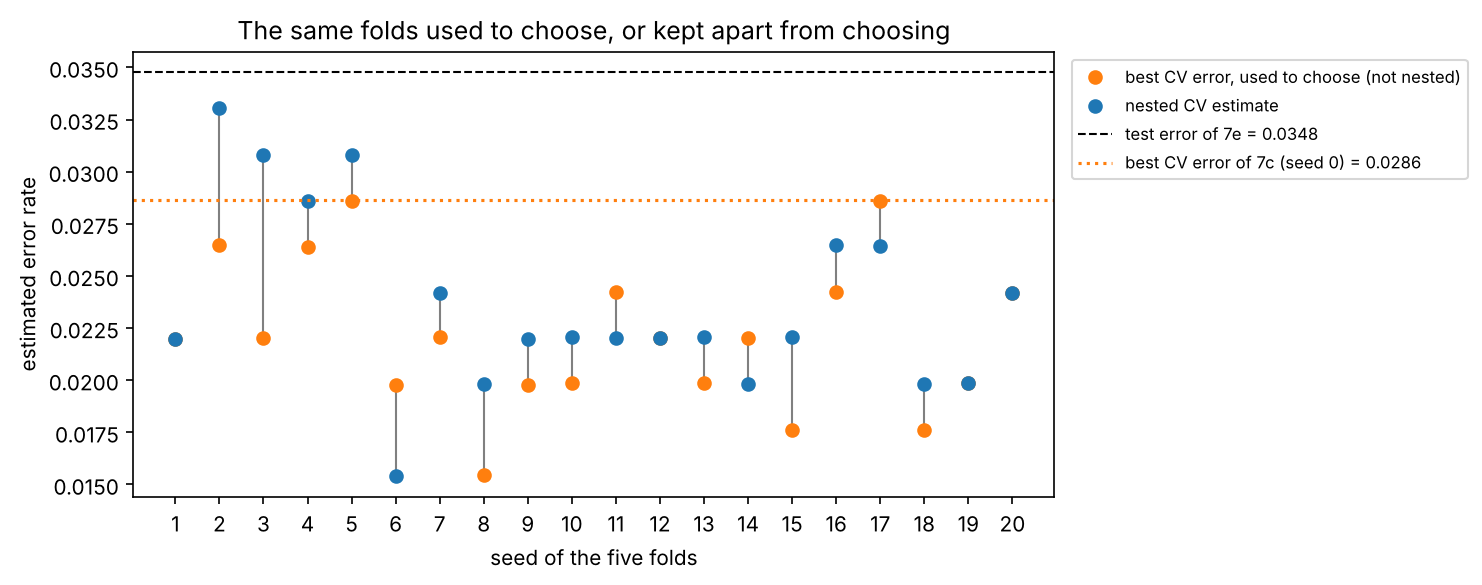

In [ ]:
def nested_cv_estimate(X, y, outer):
    '''Nested CV: for every outer fold, select on its training rows (inner seed 0), refit, score the outer fold.'''
    errors = []                                      # one outer error per outer fold
    for o_tr, o_va in outer:
        w, _ = select_by_cv(X[o_tr], y[o_tr], stratified_kfold_indices(y[o_tr], 5, seed=0))   # inner selection
        refitted = clone(candidates[w][3]).fit(X[o_tr], y[o_tr])                               # refit the winner
        errors.append(error_rate(y[o_va], refitted.predict(X[o_va])))                          # score it once
    return np.mean(errors)


rows = []                                            # one dictionary per row of the table
for s in range(1, 21):                               # 20 different sets of five folds
    folds_s = stratified_kfold_indices(y_dev, 5, seed=s)  # the five folds of this seed
    _, errs = select_by_cv(X_dev, y_dev, folds_s)    # ordinary selection on these folds (as in 7c)
    rows.append({"seed": s, "best CV error (not nested)": errs.min(),
                 "nested CV estimate": nested_cv_estimate(X_dev, y_dev, folds_s)})   # same folds as outer loop
paired = pd.DataFrame(rows).set_index("seed").round(12)  # one row per seed, two estimates

gap = paired["nested CV estimate"] - paired["best CV error (not nested)"]  # nested minus not nested
print(f"average over 20 fold sets:  best CV error {paired.iloc[:, 0].mean():.4f},"
      f"  nested {paired.iloc[:, 1].mean():.4f},  difference {gap.mean():+.4f}")
print(f"nested higher in {int((gap > 0).sum())}, equal in {int((gap == 0).sum())},"
      f" lower in {int((gap < 0).sum())} of the 20 fold sets")
print(f"spread of the best CV error over fold sets (std): {paired.iloc[:, 0].std(ddof=0):.4f}")

fig, ax = plt.subplots(figsize=(10, 4))              # one panel
x = paired.index.to_numpy()                          # the seeds 1 to 20
ax.vlines(x, paired.iloc[:, 0], paired.iloc[:, 1], color="grey", lw=1)             # a line joins each pair
ax.plot(x, paired.iloc[:, 0], "o", color="tab:orange", label="best CV error, used to choose (not nested)")
ax.plot(x, paired.iloc[:, 1], "o", color="tab:blue", label="nested CV estimate")
ax.axhline(test_error, color="black", ls="dashed", lw=1, label=f"test error of 7e = {test_error:.4f}")
ax.axhline(best_cv_error, color="tab:orange", ls="dotted", lw=1.5, label=f"best CV error of 7c (seed 0) = {best_cv_error:.4f}")
ax.set_xticks(x)                                     # a tick at every seed
ax.set_xlabel("seed of the five folds")              # x-axis label
ax.set_ylabel("estimated error rate")                # y-axis label
ax.set_title("The same folds used to choose, or kept apart from choosing")  # title
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))  # legend outside, on the right
plt.tight_layout()                                   # keep labels from overlapping
plt.show()                                           # draw the figure

**Line by line**

- `nested_cv_estimate(X, y, outer)` : the loop of 5.2 in compact form, returning only the average outer error.
- `for s in range(1, 21):` : 20 fold sets. For each, `select_by_cv` gives the ordinary (non-nested) best CV error on
  these folds, and `nested_cv_estimate` uses **the same folds** as its outer loop. The two numbers of a row are
  therefore paired: same data, same folds.
- `.round(12)` : removes floating-point dust so that equal values compare as equal.
- `gap` : nested minus non-nested for every seed. `{gap.mean():+.4f}` prints the sign explicitly.
- `(gap > 0).sum()` and so on : count the seeds where the nested estimate is higher, equal or lower.
- `paired.iloc[:, 0].std(ddof=0)` : how much the best CV error itself changes from one set of folds to another.
  `ddof=0` makes pandas use the same formula as NumPy.
- `ax.vlines(x, low, high)` : one vertical line per seed, joining its two estimates.
  Where the two estimates are equal, the blue dot is drawn on top of the orange one, so only blue is visible.
- The two horizontal lines mark the test error of 7e and the best CV error of 7c (seed 0, the folds of 7c).
- This cell needs about $20 \times (5 \times 121 + 120) = 14\,500$ fits and takes a little over a minute.

**Reading the output.**

- Over the 20 fold sets, the nested estimate is on average **higher** than the best CV error (0.0237 against 0.0221).
  It is higher for 12 fold sets, equal for 4 and lower for 4. That is the optimism of 7f, measured on real data: the
  score that was used for choosing is too low by about 0.0015 on average, roughly 0.7 of a mistake out of 454 rows.
  It is small here because the candidates are few, the signal is strong and five folds are averaged, exactly as 7f
  said.
- The best CV error itself moves from one set of folds to another with a standard deviation of 0.0035, more than
  twice the optimism. The folds of 7c (seed 0) gave 0.0286, as high as the highest of the 20 values in this plot
  (seeds 5 and 17 also give about 0.0286): they were an unusually hard set of folds. That is why, in the single
  comparison above, the nested estimate with seed 1 (0.0220) came out below 0.0286. The two numbers came from
  different folds, and fold luck was bigger than the effect being measured.
- The test error (0.0348) lies above all of these estimates. Its own standard error is 0.017 (7e), so it is within
  about one standard error of every one of them.

**Answer.**

- **The honest estimate is the nested CV estimate.** The best CV error of 7c is the minimum of 24 noisy numbers,
  computed on the same folds that picked the winner, so it is biased downwards (7f). The nested estimate scores every
  chosen model on rows that played no part in choosing it, so it estimates without that bias what the procedure
  "select by CV, then refit" achieves on new data, and that procedure is exactly how our final model was made.
  "Honest" means right **on average**, not closer in every single run: on the folds used here it happened to come
  out lower than the 7c number, and the 20 paired runs show that, with the folds held fixed, it is the higher, more
  realistic one. All three numbers agree within the uncertainty of the 115-row test set.
- **Fits:** nested CV needed $5 \times (24 \times 5 + 1) = 605$ fits, five times the 121 of `GridSearchCV` in 7d. To
  also **deploy** a model you still run the ordinary selection on all development rows (another 121 fits), because
  nested CV produces an error estimate, not a single model: its five outer folds may even choose different winners,
  as they did here.

# Summary of the answers

| exercise | question | short answer |
|---|---|---|
| 1 | LOOCV error of 5-NN | 0.0374 (17 of 454 rows), against 0.0387 for repeated 5-fold and for repeated 10-fold |
| 1 | repeating LOOCV with shuffles | identical every time: with one row per fold, a shuffle only changes the order |
| 1 | number of fits | 5, 10 and 454; LOOCV for 50 rows, a single hold-out or few folds for 5 million rows |
| 1 | std band for LOOCV | equals $\sqrt{p(1-p)}$, a function of the mean only; about 0.19 around 0.037, meaningless |
| 2 | rare class, plain 10-fold | on average 1.1 folds per split have no malignant row (77.5% of splits have at least one) |
| 2 | recall | undefined (`NaN`) in folds without malignant rows; stratification makes it defined and equal to the pooled recall |
| 2 | spread of the CV error | almost unchanged on both datasets; the gain of stratification is in the rare-class measures |
| 3 | best regression model | ridge with $\alpha = 10$: CV MSE 3075 against a baseline of 5943 |
| 3 | more data | helps the tree most, then k-NN; ridge has almost converged |
| 3 | final test | test MSE 2742, $R^2 = 0.54$; lower than the CV MSE, but within one standard error |
| 3 | stratified regression | possible by binning the target; fold targets become alike, the CV noise does not shrink |
| 4 | leakage | selecting features on all rows: CV error about 0.29; inside the folds: about 0.5, the truth |
| 4 | scaling once | at most about three mistakes of difference: a mild leak, because it uses no labels and makes no choice |
| 5 | one-SE rule | $k = 5$ and depth 2 (unchanged); it does pick simpler models for ridge ($\alpha = 100$) and k-NN regression ($k = 40$) |
| 5 | nested CV | 0.0220 on these folds; over 20 paired fold sets it is higher than the non-nested best by 0.0015 on average |
| 5 | fits | 605 for nested CV, against 121 for one `GridSearchCV` |

**The thread through all five exercises** is the question asked at the start of the exercises: *which rows was this
error computed on, and were those rows used to choose anything?* LOOCV and stratification change how the rows are
divided; leakage and the winner's curse are what happens when the rows used for scoring were also used for choosing;
nested cross-validation and the locked test set are the two ways of keeping them apart.